# Bayesian Optimization: Random Search에서 CMA-ES까지

이 Notebook은 **Bayesian Optimization(BO)을 직접 구현하면서 이해하는 것**을 목표로 한다.
라이브러리 사용법을 외우는 것이 아니라, 다음 흐름을 손으로 따라간다.

$$\text{Random Search}\ \rightarrow\ \text{RBF Kernel}\ \rightarrow\ \text{GP Prior}\ \rightarrow\ \text{GP Posterior}\ \rightarrow\ \text{Surrogate Model}\ \rightarrow\ \text{Acquisition Function}\ \rightarrow\ \text{Bayesian Optimization}$$

마지막에는 다음 비교까지 한다.

$$\text{Random Search} \quad vs \quad \text{Bayesian Optimization} \quad vs \quad \text{CMA-ES}$$

## Section 0. 학습 목표

이 Notebook을 끝내면 다음을 설명할 수 있어야 한다.

1. 왜 Random Search가 baseline인지
2. RBF kernel이 무엇을 표현하는지
3. GP prior가 무엇인지
4. 데이터를 관측하면 posterior가 어떻게 바뀌는지
5. posterior mean과 uncertainty의 의미
6. GP가 surrogate model로 왜 적합한지
7. acquisition function이 왜 필요한지
8. exploration과 exploitation의 차이
9. Expected Improvement가 무엇인지
10. BO가 iteration마다 어떻게 동작하는지
11. Random Search와 BO의 sample efficiency 차이
12. CMA-ES와 BO의 철학적 차이

## 읽는 순서

모든 핵심 개념은 **직관 → 수식 → 코드 → 그림 → 실험** 순서로 진행된다.
수식을 완전히 외울 필요는 없지만, 각 수식이 코드의 어느 줄에 대응하는지는 확인하기 바란다.

## 필요한 패키지

```python
# pip install numpy scipy matplotlib scikit-learn cma
```

`cma`는 마지막 비교 실험에서만 사용한다. 나머지는 모두 직접 구현한다.


## Section 1. Black-box Objective Function

BO가 풀고자 하는 문제는 다음과 같은 **black-box 최적화**이다.

$$\min_{x \in \mathcal{X}} f(x)$$

여기서 black-box란 다음을 의미한다.

- $f$의 해석적 형태를 모르거나, 알더라도 gradient를 쓰지 않는다.
- $f(x)$ 한 번의 평가가 **비싸다**. (실험이나 시뮬레이션 한 번에 수 분 ~ 수 시간)
- 따라서 **가능한 한 적은 평가 횟수**로 좋은 해를 찾아야 한다.

교육용으로는 1D toy function을 쓴다. local minimum이 여러 개 있고 global minimum이 한 곳에 있는 함수다.


In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

np.set_printoptions(precision=4, suppress=True)
print("numpy", np.__version__)


numpy 2.3.1


In [2]:
def objective(x):
    """비싼 black-box objective. 우리는 이 함수의 gradient를 쓰지 않는다."""
    x = np.asarray(x, dtype=float)
    return 0.15 * (x - 2.0) ** 2 + np.sin(3.0 * x) + 0.3 * np.sin(7.0 * x)


BOUNDS = (-2.0, 6.0)  # search domain

# dense grid로 global optimum을 근사한다 (실제 문제에서는 알 수 없음)
grid_dense = np.linspace(*BOUNDS, 200001)
y_dense = objective(grid_dense)
idx = int(np.argmin(y_dense))

GLOBAL_X = float(grid_dense[idx])
GLOBAL_F = float(y_dense[idx])

print("Approximate global optimum:")
print(f"  x    = {GLOBAL_X:.6f}")
print(f"  f(x) = {GLOBAL_F:.6f}")


Approximate global optimum:
  x    = 1.576160
  f(x) = -1.272713


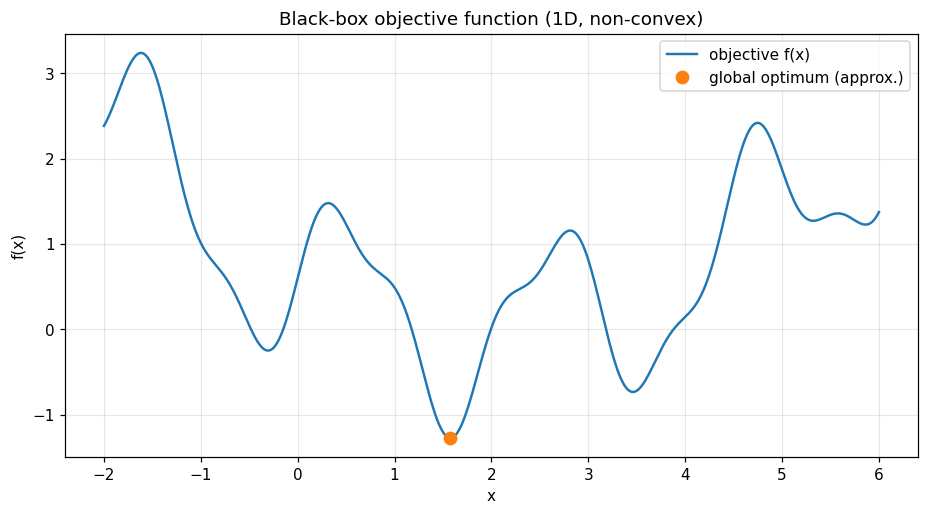

local minima 개수 확인용: 기울기 부호가 바뀌는 지점
  대략 10 개의 stationary point 근처 지점이 있다


In [3]:
x_plot = np.linspace(*BOUNDS, 800)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(x_plot, objective(x_plot), linewidth=1.6, label="objective f(x)")
ax.plot(GLOBAL_X, GLOBAL_F, "o", markersize=8, label="global optimum (approx.)")
ax.set_title("Black-box objective function (1D, non-convex)")
ax.set_xlabel("x")
ax.set_ylabel("f(x)")
ax.legend()
fig.savefig(os.path.join(FIG_DIR, "01_objective.png"), bbox_inches="tight")
plt.show()

print("local minima 개수 확인용: 기울기 부호가 바뀌는 지점")
sign = np.sign(np.gradient(y_dense))
turn = np.where(np.diff(sign) != 0)[0]
print(f"  대략 {len(turn)} 개의 stationary point 근처 지점이 있다")


**관찰**: 이 함수는 local minimum이 여러 개다. Random Search나 gradient descent는 이 local minimum 중 어디에 갇힐지 알 수 없다.
BO는 "지금까지 관측한 값"과 "아직 관측하지 않아 불확실한 곳"을 함께 고려해서 다음 실험점을 고른다.

### 학습 확인 질문

1. 이 함수가 "black-box"라는 말은 구체적으로 무엇을 못 한다는 뜻인가?
2. dense grid로 global optimum을 구했는데, 실제 BO 문제에서는 이 값을 알 수 없는 이유는 무엇인가?


## Section 2. Random Search

가장 단순한 baseline이다. 다음 후보를 이전 결과와 **무관하게** 뽑는다.

$$x_{t+1} \sim p(x)$$

여기서 $p(x)$는 search domain 위의 uniform 분포다. 이전 평가 결과는 전혀 사용되지 않는다.
그럼에도 baseline으로 중요한 이유는, 평가 횟수가 늘어날수록 **최적해에 수렴하는 속도가 이론적으로 보장**되기 때문이다.
BO가 이 baseline보다 나은지 판단하는 기준이 된다.


In [4]:
def random_search(objective, bounds, n_evals, seed=0):
    """Uniform random sampling으로 objective를 평가한다.

    Returns
    -------
    X : (n_evals,) array, 평가한 x
    y : (n_evals,) array, 평가한 f(x)
    """
    rng = np.random.default_rng(seed)
    low, high = bounds
    X = rng.uniform(low, high, size=n_evals)
    y = objective(X)
    return X, y


N_EVALS_RS = 15
X_rs, y_rs = random_search(objective, BOUNDS, n_evals=N_EVALS_RS, seed=0)

best_idx = int(np.argmin(y_rs))
print(f"Random Search ({N_EVALS_RS} evaluations)")
print(f"  best x = {X_rs[best_idx]:.4f}")
print(f"  best f = {y_rs[best_idx]:.4f}")
print(f"  regret = {y_rs[best_idx] - GLOBAL_F:.4f}")


Random Search (15 evaluations)
  best x = 3.8360
  best f = -0.0693
  regret = 1.2034


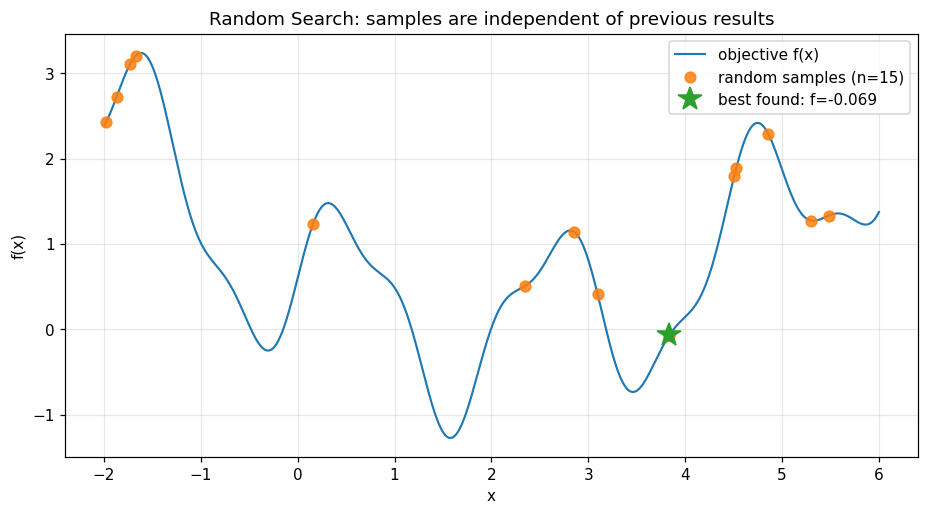

In [5]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(x_plot, objective(x_plot), linewidth=1.4, label="objective f(x)")
ax.plot(X_rs, y_rs, "o", markersize=7, alpha=0.85, label=f"random samples (n={N_EVALS_RS})")
ax.plot(X_rs[best_idx], y_rs[best_idx], "*", markersize=16,
        label=f"best found: f={y_rs[best_idx]:.3f}")
ax.set_title("Random Search: samples are independent of previous results")
ax.set_xlabel("x")
ax.set_ylabel("f(x)")
ax.legend()
fig.savefig(os.path.join(FIG_DIR, "02_random_search.png"), bbox_inches="tight")
plt.show()


그림에서 점들이 domain 전체에 고르게 흩어져 있는 것을 볼 수 있다. 15번 중 좋은 영역에 2~3번 들어가면 운이 좋은 것이고,
그 영역에 다시 집중해서 파고들지는 않는다. **이전 결과를 활용하지 않기 때문**이다.

### 학습 확인 질문

1. Random Search는 왜 "baseline"이라고 부르는가?
2. 평가 예산이 15회로 제한되어 있을 때, Random Search의 가장 큰 비효율은 무엇인가?


## Section 3. RBF Kernel

GP는 "함수들에 대한 분포"다. 그 분포의 성격은 **covariance function(kernel)** 이 결정한다.
가장 널리 쓰이는 것이 RBF(radial basis function) kernel이다.

$$k(x,x') = \sigma_f^2 \exp\left(-\frac{(x-x')^2}{2\ell^2}\right)$$

- $\sigma_f^2$: 함수 값의 진폭(amplitude). 함수가 평균에서 얼마나 멀리 출렁일 수 있는가.
- $\ell$: length scale. **두 점의 거리가 어느 정도일 때까지 서로 비슷한 값**을 가질 수 있는가.

직관: $k(x,x')$는 "$x$에서 $f$를 관측했을 때 $x'$에서의 $f$에 대해 얼마나 알 수 있는가"를 나타내는 유사도다.
$\ell$이 작으면 $k$가 빠르게 0으로 떨어져 이웃 정보가 거의 전달되지 않고, $\ell$이 크면 멀리까지 전달된다.


In [5]:
def rbf_kernel(X1, X2, length_scale=1.0, sigma_f=1.0):
    """RBF kernel matrix K[i, j] = k(X1[i], X2[j]).

    Parameters
    ----------
    X1, X2 : (n,) or (n, d) array
    length_scale : float, l
    sigma_f : float, signal variance

    Returns
    -------
    K : (len(X1), len(X2)) array
    """
    X1 = np.atleast_2d(np.asarray(X1, dtype=float)).reshape(-1, 1)
    X2 = np.atleast_2d(np.asarray(X2, dtype=float)).reshape(-1, 1)
    sq_dist = (X1 - X2.T) ** 2
    return sigma_f ** 2 * np.exp(-0.5 * sq_dist / length_scale ** 2)


# 손으로 확인: 같은 점이면 k = sigma_f^2, 멀어지면 0
print("k(0, 0)   =", rbf_kernel([0.0], [0.0])[0, 0])
print("k(0, 1)   =", rbf_kernel([0.0], [1.0], length_scale=1.0)[0, 0])
print("k(0, 3)   =", rbf_kernel([0.0], [3.0], length_scale=1.0)[0, 0])


k(0, 0)   = 1.0
k(0, 1)   = 0.6065306597126334
k(0, 3)   = 0.011108996538242306


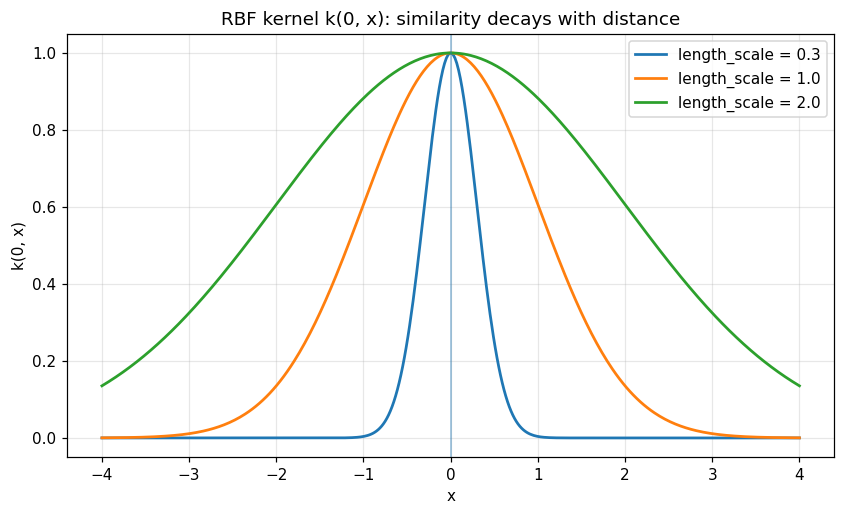

In [5]:
x_k = np.linspace(-4, 4, 400)
anchor = np.array([0.0])
length_scales = [0.3, 1.0, 2.0]

fig, ax = plt.subplots(figsize=(9, 5))
for ell in length_scales:
    k_vals = rbf_kernel(anchor, x_k, length_scale=ell, sigma_f=1.0)[0]
    ax.plot(x_k, k_vals, linewidth=1.8, label=f"length_scale = {ell}")
ax.axvline(0.0, linewidth=1.0, alpha=0.5)
ax.set_title("RBF kernel k(0, x): similarity decays with distance")
ax.set_xlabel("x")
ax.set_ylabel("k(0, x)")
ax.legend()
fig.savefig(os.path.join(FIG_DIR, "03_rbf_kernel.png"), bbox_inches="tight")
plt.show()


- 작은 $\ell$: kernel이 좁게 퍼진다 → **빠르게 변하는 함수**를 허용 (유연하지만 과적합 위험)
- 큰 $\ell$: kernel이 넓게 퍼진다 → **매끄러운 함수**를 가정 (관측 사이를 길게 보간)

### 학습 확인 질문

1. $\ell \to 0$에 가까워지면 GP prior에서 샘플링한 함수는 어떤 모양이 되는가?
2. kernel matrix $K$의 대각 성분은 항상 $\sigma_f^2$인 이유는 무엇인가?


## Section 4. Gaussian Process Prior

관측 데이터가 하나도 없을 때, GP는 함수에 대한 **사전 분포(prior)** 를 정의한다.

$$f(X) \sim \mathcal{N}(0, K)$$

즉 하나의 함수를 정하는 것이 아니라, **함수들의 분포**를 정한다. 평균은 0이라 가정하고(데이터가 없으니 특별히 선호할 곳이 없다),
함수들 사이의 상관관계는 $K$가 결정한다.

절차는 정확히 세 단계다.

1. grid $X$ 생성
2. covariance matrix $K = k(X, X)$ 계산
3. multivariate Gaussian에서 샘플 추출

$K$가 positive semi-definite이어야 샘플링이 가능하다. RBF kernel은 항상 그렇다.


In [6]:
X_grid = np.linspace(*BOUNDS, 200)

print("X_grid shape:", X_grid.shape)

K_prior = rbf_kernel(X_grid, X_grid, length_scale=1.0, sigma_f=1.0)
print("K shape      :", K_prior.shape)
print("symmetric    :", np.allclose(K_prior, K_prior.T))
print("eigenvalues>0:", np.all(np.linalg.eigvalsh(K_prior) > -1e-8))


X_grid shape: (200,)
K shape      : (200, 200)
symmetric    : True
eigenvalues>0: True


prior_samples.shape: (5, 200)


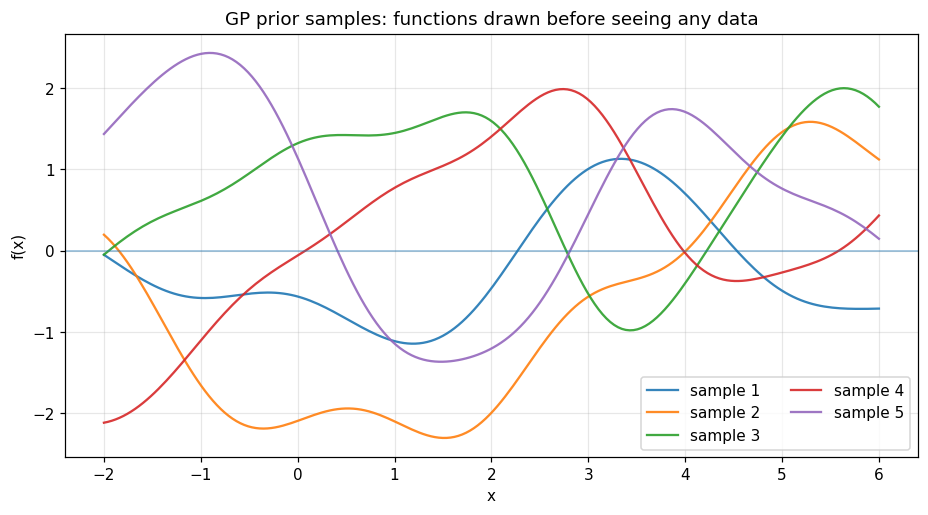

In [9]:
rng = np.random.default_rng(1)
n_samples = 5
prior_samples = rng.multivariate_normal(mean=np.zeros(len(X_grid)), cov=K_prior, size=n_samples)
print("prior_samples.shape:", prior_samples.shape)

fig, ax = plt.subplots(figsize=(10, 5))
for i in range(n_samples):
    ax.plot(X_grid, prior_samples[i], linewidth=1.5, alpha=0.9, label=f"sample {i + 1}")
ax.axhline(0.0, linewidth=1.0, alpha=0.5)
ax.set_title("GP prior samples: functions drawn before seeing any data")
ax.set_xlabel("x")
ax.set_ylabel("f(x)")
ax.legend(ncol=2)
fig.savefig(os.path.join(FIG_DIR, "04_gp_prior_samples.png"), bbox_inches="tight")
plt.show()


샘플들이 **매끄럽게 이어지고**, 서로 다른 함수지만 같은 "성격"(부드러움, 진폭)을 공유하는 것을 볼 수 있다.
이 성격을 정하는 것이 kernel과 hyperparameter($\ell, \sigma_f$)다.

### 학습 확인 질문

1. GP prior에서 함수를 여러 개 샘플링했을 때, 이 함수들의 공통점은 무엇인가?
2. $K$의 비대각 성분이 크면(즉 $\ell$이 크면) 샘플 함수는 어떤 성질을 갖는가?


## Section 5. Gaussian Process Posterior

이제 몇 개의 점을 관측했다고 하자. 관측값 $y$가 노이즈를 포함한다고 하면

$$y = f(x) + \varepsilon,\qquad \varepsilon \sim \mathcal{N}(0, \sigma_n^2)$$

관측 이후의 함수에 대한 분포(posterior)는 **multivariate Gaussian의 conditional distribution** 공식으로 주어진다.

$$\mu_* = K_*^{\top}(K + \sigma_n^2 I)^{-1} y$$

$$\Sigma_* = K_{**} - K_*^{\top}(K + \sigma_n^2 I)^{-1} K_*$$

여기서

- $K = k(X, X)$: 학습점끼리의 covariance $(n \times n)$
- $K_* = k(X, X_*)$: 학습점과 예측점 사이 $(n \times m)$
- $K_{**} = k(X_*, X_*)$: 예측점끼리 $(m \times m)$

이 공식의 의미는 하나다. **관측한 점 근처에서는 $K_*$가 커지므로 posterior variance가 줄어들고, posterior mean이 관측값을 따라간다.**

구현 시 주의: `np.linalg.inv`를 쓰지 말고 `np.linalg.solve`를 쓴다 (수치적으로 더 안정적이고 빠르다).


In [6]:
def gp_posterior(X_train, y_train, X_test, length_scale=1.0, sigma_f=1.0, sigma_n=1e-6):
    """GP posterior mean and variance at X_test given noisy observations.

    Parameters
    ----------
    X_train, y_train : (n,) arrays
    X_test : (m,) array
    length_scale, sigma_f : kernel hyperparameters
    sigma_n : observation noise standard deviation

    Returns
    -------
    mu : (m,) posterior mean
    var : (m,) posterior variance (diagonal of Sigma_*)
    """
    X_train = np.asarray(X_train, dtype=float).ravel()
    y_train = np.asarray(y_train, dtype=float).ravel()
    X_test = np.asarray(X_test, dtype=float).ravel()

    K = rbf_kernel(X_train, X_train, length_scale, sigma_f)
    K_star = rbf_kernel(X_train, X_test, length_scale, sigma_f)      # (n, m)
    K_starstar = rbf_kernel(X_test, X_test, length_scale, sigma_f)   # (m, m)

    A = K + sigma_n ** 2 * np.eye(len(X_train))

    # A^{-1} y  and  A^{-1} K_*  를 solve로 한 번에 구한다
    alpha = np.linalg.solve(A, y_train)          # (n,)
    mu = K_star.T @ alpha                        # (m,)

    V = np.linalg.solve(A, K_star)               # (n, m)
    cov = K_starstar - K_star.T @ V              # (m, m)
    var = np.diag(cov).copy()
    var = np.clip(var, 1e-12, None)
    return mu, var


In [7]:
X_train = np.array([-1.5, 0.0, 2.2, 4.8])
y_train = objective(X_train)

mu, var = gp_posterior(X_train, y_train, x_plot, length_scale=1.0, sigma_n=1e-6)

print("X_train :", X_train)
print("y_train :", np.round(y_train, 4))
print("posterior mean at train points:", np.round(
    gp_posterior(X_train, y_train, X_train)[0], 4))
print("posterior std  at train points:", np.round(
    np.sqrt(gp_posterior(X_train, y_train, X_train)[1]), 6))


X_train : [-1.5  0.   2.2  4.8]
y_train : [3.0789 0.6    0.4085 2.387 ]
posterior mean at train points: [3.0789 0.6    0.4085 2.387 ]
posterior std  at train points: [0. 0. 0. 0.]


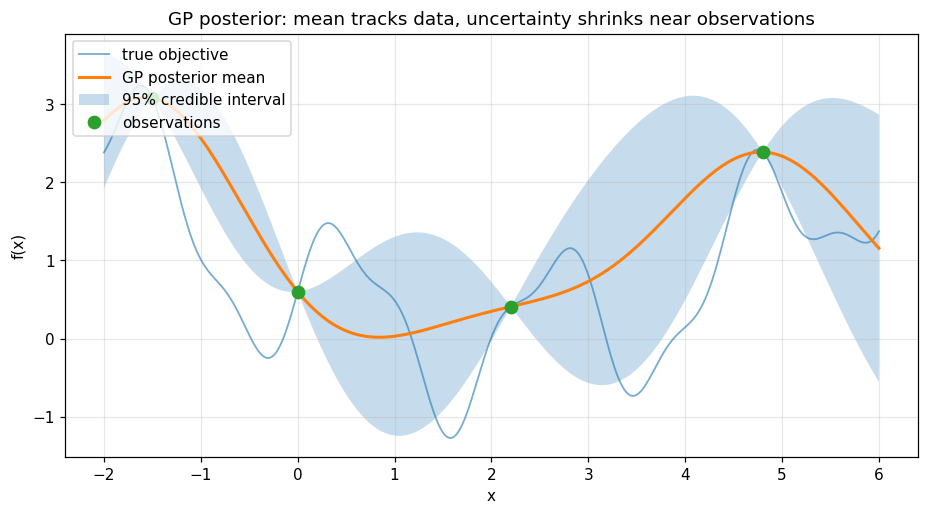

In [12]:
std = np.sqrt(var)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(x_plot, objective(x_plot), linewidth=1.2, alpha=0.6, label="true objective")
ax.plot(x_plot, mu, linewidth=2.0, label="GP posterior mean")
ax.fill_between(x_plot, mu - 1.96 * std, mu + 1.96 * std, alpha=0.25,
                label="95% credible interval")
ax.plot(X_train, y_train, "o", markersize=8, label="observations")
ax.set_title("GP posterior: mean tracks data, uncertainty shrinks near observations")
ax.set_xlabel("x")
ax.set_ylabel("f(x)")
ax.legend(loc="upper left")
fig.savefig(os.path.join(FIG_DIR, "05_gp_posterior.png"), bbox_inches="tight")
plt.show()


그림에서 세 가지를 확인하자.

1. 관측점에서 posterior mean이 관측값과 거의 일치한다 ($\sigma_n$이 작기 때문).
2. 관측점에서 credible interval 폭이 거의 0으로 줄어든다 → **uncertainty 감소**.
3. 관측점 사이, 특히 양 끝($x < -1.5$, $x > 4.8$)에서는 prior 수준으로 다시 벌어진다 → **데이터가 없는 곳은 모른다**.

수식으로 보면, 관측점과 멀어지면 $K_* \to 0$이므로 $\Sigma_* \to K_{**}$, 즉 prior variance로 돌아간다.

### 학습 확인 질문

1. 왜 관측점 근처에서 uncertainty가 감소하는가?
2. $K_*$가 거의 0이면 posterior variance는 어떻게 되는가?
3. $\sigma_n$을 크게 하면 posterior mean과 variance는 각각 어떻게 변하는가?


## Section 6. Surrogate Model로서의 GP

지금까지 GP를 regression 도구로 봤다. BO에서는 **surrogate model**(대리 모델)로 쓴다.

> 실제 objective $f(x)$는 매우 비싸다. 그래서 이미 평가한 데이터만으로 값싼 근사 모델 $\hat f(x)$를 만든다.

핵심은 GP가 **두 가지를 동시에** 준다는 점이다.

$$\mu(x) \qquad \text{and} \qquad \sigma(x)$$

즉 `prediction + uncertainty`다.

일반적인 회귀 모델(선형회귀, 신경망)은 예측값만 준다. 예측이 얼마나 믿을 만한지 알려면 별도의 작업이 필요하다.
GP는 posterior distribution 자체가 uncertainty를 포함하므로, **"어디를 더 실험해야 하는가"를 결정하는 데 직접 쓸 수 있다.**
이것이 BO가 GP를 surrogate로 쓰는 이유다.


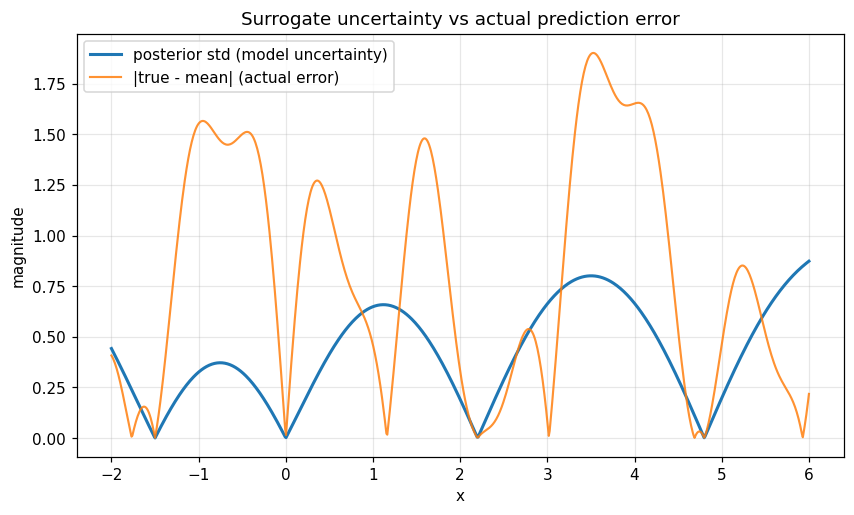

correlation(std, |error|) = 0.347


In [13]:
# surrogate의 품질을 한 눈에: 예측 오차와 불확실성의 관계
mu_t, var_t = gp_posterior(X_train, y_train, x_plot, length_scale=1.0, sigma_n=1e-6)
err = np.abs(objective(x_plot) - mu_t)
std_t = np.sqrt(var_t)

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(x_plot, std_t, linewidth=2.0, label="posterior std (model uncertainty)")
ax.plot(x_plot, err, linewidth=1.4, alpha=0.85, label="|true - mean| (actual error)")
ax.set_title("Surrogate uncertainty vs actual prediction error")
ax.set_xlabel("x")
ax.set_ylabel("magnitude")
ax.legend()
fig.savefig(os.path.join(FIG_DIR, "06_surrogate_uncertainty.png"), bbox_inches="tight")
plt.show()

print("correlation(std, |error|) =", round(float(np.corrcoef(std_t, err)[0, 1]), 3))


상관계수는 0.3 정도로 아주 높지는 않다. 그 이유는 오차 $|f-\mu|$에 **bias**가 섞여 있기 때문이다:
관측점 근처에서도 $\mu$는 함수의 굴곡을 완전히 맞히지 못하므로 오차가 0이 아니다.
반면 $\sigma(x)$는 순수하게 "데이터가 없는 정도"만 반영한다.

그럼에도 중요한 성질은 유지된다: **데이터가 없는 구간에서는 $\sigma$가 크고, 관측점 근처에서는 작다.**
BO가 실제로 쓰는 것은 $\sigma$의 절댓값이 아니라 **어디가 상대적으로 더 불확실한가**라는 순서다.
그 순서를 이용해 다음 실험 위치를 정한다. 이것이 다음 두 섹션의 주제다.


## Section 7. Exploration vs Exploitation

acquisition function을 이해하려면 먼저 이 trade-off를 이해해야 한다.

### Exploitation (이용)

posterior mean $\mu(x)$가 좋은(작은) 위치를 고른다.

$$x_{\text{next}} = \arg\min_x \mu(x)$$

지금까지의 정보만 믿고 **가장 좋아 보이는 곳**을 파고든다.
문제: GP mean은 관측점 근처에서만 믿을 만하고, 나머지는 prior(0)로 되돌아간다. mean만 보면 **아직 안 가본 곳의 진짜 좋은 값**을 영원히 놓칠 수 있다.

### Exploration (탐색)

uncertainty $\sigma(x)$가 큰 위치를 고른다.

$$x_{\text{next}} = \arg\max_x \sigma(x)$$

**모르는 곳**을 확인해서 정보를 얻는다.
문제: 정보만 얻고 성능은 전혀 개선되지 않을 수 있다.

### BO의 선택

BO는 두 신호를 **하나의 점수 함수**로 결합하고, 그 점수의 최대점을 다음 실험으로 삼는다.

$$\text{acquisition}(x) = g\big(\mu(x), \sigma(x)\big)$$

이렇게 하면 "좋아 보이면서 + 아직 불확실한" 곳이 자동으로 선택된다. 다음 섹션에서 $g$의 가장 대표적인 형태인 EI를 구현한다.


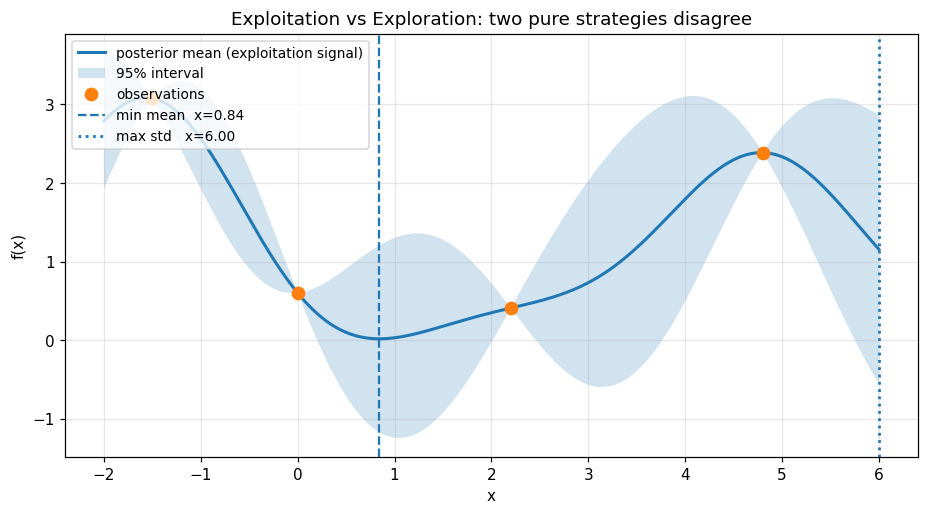

pure exploitation choice: x = 0.844
pure exploration  choice: x = 6.000


In [14]:
# 같은 posterior에서 exploitation 후보와 exploration 후보를 각각 계산
mu_e, var_e = gp_posterior(X_train, y_train, x_plot, length_scale=1.0, sigma_n=1e-6)
std_e = np.sqrt(var_e)

x_exploit = x_plot[int(np.argmin(mu_e))]
x_explore = x_plot[int(np.argmax(std_e))]

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(x_plot, mu_e, linewidth=2.0, label="posterior mean (exploitation signal)")
ax.fill_between(x_plot, mu_e - 1.96 * std_e, mu_e + 1.96 * std_e, alpha=0.2,
                label="95% interval")
ax.plot(X_train, y_train, "o", markersize=8, label="observations")
ax.axvline(x_exploit, linestyle="--", linewidth=1.5,
           label=f"min mean  x={x_exploit:.2f}")
ax.axvline(x_explore, linestyle=":", linewidth=1.8,
           label=f"max std   x={x_explore:.2f}")
ax.set_title("Exploitation vs Exploration: two pure strategies disagree")
ax.set_xlabel("x")
ax.set_ylabel("f(x)")
ax.legend(loc="upper left", fontsize=9)
fig.savefig(os.path.join(FIG_DIR, "07_explore_exploit.png"), bbox_inches="tight")
plt.show()

print(f"pure exploitation choice: x = {x_exploit:.3f}")
print(f"pure exploration  choice: x = {x_explore:.3f}")


두 전략이 서로 다른 곳을 가리키는 것을 볼 수 있다. 어느 한쪽만 쓰면 실패한다.

### 학습 확인 질문

1. 왜 GP mean만으로 next point를 고르면 안 되는가?
2. Exploration과 Exploitation이 왜 동시에 필요한가?
3. objective evaluation이 매우 비쌀수록 BO가 유리한 이유는 무엇인가?


## Section 8. Expected Improvement

acquisition function 중 가장 널리 쓰이는 **Expected Improvement (EI)** 를 직접 구현한다. 최소화 문제 기준이다.

현재까지의 best 값을 $f_{\text{best}} = \min(y)$라 하자. 어떤 점 $x$를 평가했을 때 얻게 될 improvement는

$$I(x) = \max\big(f_{\text{best}} - f(x),\ 0\big)$$

$f(x)$는 아직 모르지만, GP posterior에 따르면 $f(x) \sim \mathcal{N}(\mu(x), \sigma^2(x))$다.
따라서 $I(x)$도 확률변수이고, 그 **기댓값**을 최대화하면 된다.

$$EI(x) = \mathbb{E}[I(x)]$$

이 기댓값은 closed form으로 계산된다. $Z = \dfrac{f_{\text{best}} - \mu(x) - \xi}{\sigma(x)}$라 두면

$$EI(x) = \big(f_{\text{best}} - \mu(x) - \xi\big)\Phi(Z) + \sigma(x)\phi(Z)$$

여기서 $\Phi$는 standard normal CDF, $\phi$는 PDF다. $\xi \geq 0$는 exploration을 조금 더 밀어주는 파라미터다.

**직관적으로 읽는 법**: 첫 항은 "mean이 좋을수록 커지고"(exploitation), 두 항 모두 "$\sigma$가 클수록 커진다"(exploration).
$\sigma = 0$이면 EI도 0이 되어 이미 아는 곳은 절대 선택되지 않는다.


In [15]:
def expected_improvement(mu, sigma, best_y, xi=0.01):
    """Minimization 기준 Expected Improvement.

    Parameters
    ----------
    mu, sigma : (m,) posterior mean and std
    best_y : float, 지금까지 관측한 최소값
    xi : float, exploration 여유 파라미터

    Returns
    -------
    ei : (m,) array
    """
    mu = np.asarray(mu, dtype=float)
    sigma = np.asarray(sigma, dtype=float)
    sigma = np.maximum(sigma, 1e-12)          # 0으로 나누기 방지

    improvement = best_y - mu - xi
    Z = improvement / sigma
    ei = improvement * norm.cdf(Z) + sigma * norm.pdf(Z)
    ei[sigma < 1e-11] = 0.0
    return np.maximum(ei, 0.0)


In [16]:
# 간단한 sanity check: sigma -> 0 이면 EI -> 0, mean이 좋을수록 EI가 크다
mu_test = np.array([0.0, 0.0, 0.0])
sig_test = np.array([1.0, 0.1, 1e-12])
print("EI (sigma 큼/작음/0):", np.round(expected_improvement(mu_test, sig_test, best_y=0.0), 6))
print("EI (mean 낮을수록 큼) :", np.round(
    expected_improvement(np.array([-1.0, 0.0, 1.0]), np.ones(3) * 0.5, best_y=0.0), 4))


EI (sigma 큼/작음/0): [0.394  0.0351 0.    ]
EI (mean 낮을수록 큼) : [0.9945 0.1945 0.004 ]


출력에서 확인할 것:

- $\sigma \to 0$이면 EI $\to 0$ (이미 확실히 아는 곳은 갈 이유가 없다)
- $\mu$가 작을수록 EI가 크다 (mean이 좋은 곳을 선호)
- 하지만 $\sigma$가 충분히 크면 mean이 나빠도 EI가 남는다 (불확실한 곳도 후보)

### 학습 확인 질문

1. EI에서 $\xi$를 크게 하면 선택이 exploitation 쪽으로 가는가, exploration 쪽으로 가는가?
2. $\sigma(x) = 0$인 점의 EI가 정확히 0인 이유를 수식으로 설명해 보라.


## Section 9. Acquisition Function 시각화

이제 같은 posterior에서 EI를 계산하고, **EI를 최대화하는 위치**를 다음 실험점으로 고른다.

$$x_{\text{next}} = \arg\max_x EI(x)$$

아래 두 그림은 같은 x grid, 같은 GP posterior를 사용하지만 서로 다른 것을 보여준다. (spec 규칙에 따라 subplot을 쓰지 않고 각각 별도 figure로 만든다.)


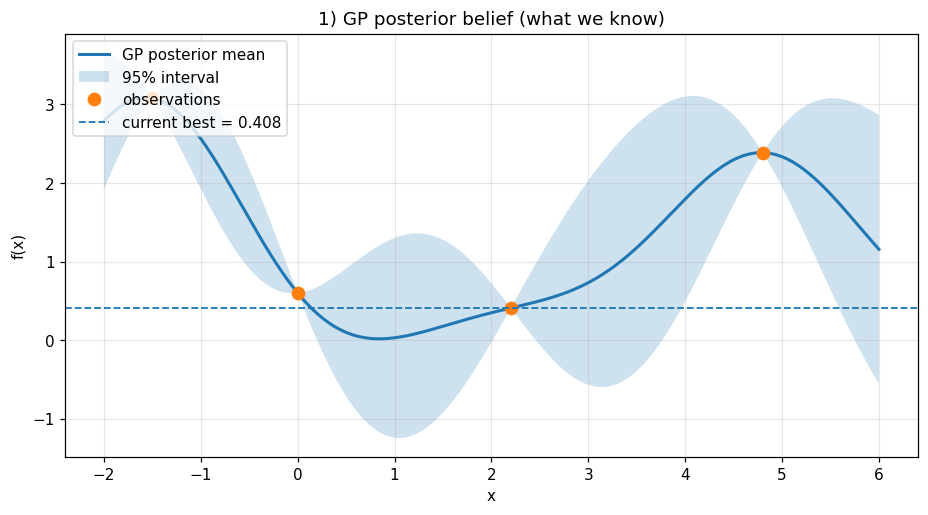

In [17]:
best_y = float(np.min(y_train))
ei_vals = expected_improvement(mu_e, std_e, best_y=best_y, xi=0.01)
x_next = x_plot[int(np.argmax(ei_vals))]

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(x_plot, mu_e, linewidth=2.0, label="GP posterior mean")
ax.fill_between(x_plot, mu_e - 1.96 * std_e, mu_e + 1.96 * std_e, alpha=0.22,
                label="95% interval")
ax.plot(X_train, y_train, "o", markersize=8, label="observations")
ax.axhline(best_y, linestyle="--", linewidth=1.2, label=f"current best = {best_y:.3f}")
ax.set_title("1) GP posterior belief (what we know)")
ax.set_xlabel("x")
ax.set_ylabel("f(x)")
ax.legend(loc="upper left")
fig.savefig(os.path.join(FIG_DIR, "08_gp_belief_for_ei.png"), bbox_inches="tight")
plt.show()


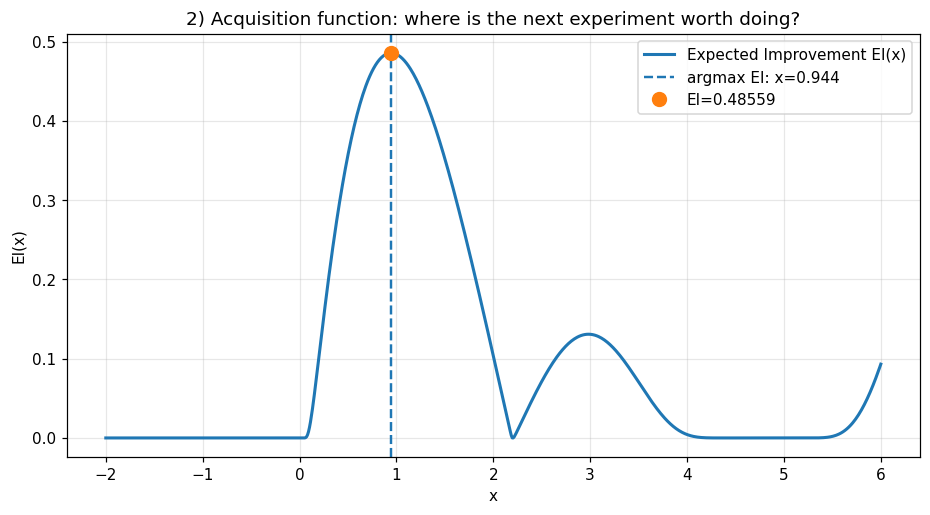

current best   = 0.4085
selected x_next= 0.9437
EI(x_next)     = 0.485593
posterior mu   = 0.0221
posterior std  = 0.6375


In [18]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(x_plot, ei_vals, linewidth=2.0, label="Expected Improvement EI(x)")
ax.axvline(x_next, linestyle="--", linewidth=1.6,
           label=f"argmax EI: x={x_next:.3f}")
ax.plot(x_next, ei_vals.max(), "o", markersize=9, label=f"EI={ei_vals.max():.5f}")
ax.set_title("2) Acquisition function: where is the next experiment worth doing?")
ax.set_xlabel("x")
ax.set_ylabel("EI(x)")
ax.legend()
fig.savefig(os.path.join(FIG_DIR, "09_expected_improvement.png"), bbox_inches="tight")
plt.show()

print(f"current best   = {best_y:.4f}")
print(f"selected x_next= {x_next:.4f}")
print(f"EI(x_next)     = {ei_vals.max():.6f}")
print(f"posterior mu   = {np.interp(x_next, x_plot, mu_e):.4f}")
print(f"posterior std  = {np.interp(x_next, x_plot, std_e):.4f}")


EI 곡선이 봉우리를 갖는 위치는 대개 **"mean이 괜찮으면서 uncertainty가 아직 큰"** 영역이다.
순수 exploitation 위치(mean 최소)와 순수 exploration 위치(max std)의 중간 어딘가가 되는 경우가 많다. 이것이 trade-off의 실제 모습이다.


## Section 10. One BO Iteration

지금 가진 데이터에서 **단 한 번의 BO iteration**을 실행한다. 순서는 정확히 다음과 같다.

```text
1. GP fit            (posterior mean/var 계산)
2. EI 계산
3. EI 최대 위치 선택
4. 실제 objective 평가   <-- 여기서만 비싼 비용이 든다
5. training data에 추가
```

BO의 계산 비용은 1~3단계(싸다)에 있고, 4단계(비싸다)는 오직 한 번만 일어난다.
**싼 계산을 많이 써서 비싼 평가를 아끼는 것**이 BO의 본질이다.


In [19]:
X_iter = X_train.copy()
y_iter = y_train.copy()

# 1~2. GP fit + EI
mu_i, var_i = gp_posterior(X_iter, y_iter, x_plot, length_scale=1.0, sigma_n=1e-6)
std_i = np.sqrt(var_i)
ei_i = expected_improvement(mu_i, std_i, best_y=float(np.min(y_iter)), xi=0.01)

# 3. next candidate
x_next_i = float(x_plot[int(np.argmax(ei_i))])

# 4. 실제 objective 평가 (유일하게 비싼 단계)
y_next_i = float(objective(x_next_i))

# 5. 데이터 추가
X_iter = np.append(X_iter, x_next_i)
y_iter = np.append(y_iter, y_next_i)

print(f"Current best      = {np.min(y_iter[:-1]):.6f}")
print(f"Selected x_next   = {x_next_i:.6f}")
print(f"EI(x_next)        = {ei_i.max():.6f}")
print(f"Observed f(x_next)= {y_next_i:.6f}")
print(f"New best          = {np.min(y_iter):.6f}")


Current best      = 0.408477
Selected x_next   = 0.943680
EI(x_next)        = 0.485593
Observed f(x_next)= 0.568060
New best          = 0.408477


## Section 11. Full Bayesian Optimization Loop

이제 한 iteration을 반복문으로 감싼다. 초기 $n_{\text{initial}}$개 점은 random sampling으로 채우고(어디서 시작할지 모르므로),
그 이후부터는 EI로 다음 점을 고른다.

매 iteration마다 다음을 history에 저장한다. 나중에 진행 과정을 그림으로 되돌려 보기 위해서다.

```python
{
    "iteration": ...,
    "X": ..., "y": ...,          # 이 시점까지의 관측
    "mu": ..., "sigma": ...,     # grid 위 posterior
    "ei": ...,                   # grid 위 EI
    "x_next": ..., "y_next": ...,  # 이번에 고르고 평가한 점
}
```


In [20]:
def bayesian_optimization(objective, bounds, n_initial=3, n_iterations=12,
                           length_scale=1.0, sigma_f=1.0, sigma_n=1e-6,
                           xi=0.01, grid_size=400, seed=0, verbose=True):
    """1D Bayesian Optimization with a hand-written GP and EI.

    Returns
    -------
    X, y : (n_initial + n_iterations,) arrays, 평가한 모든 점
    history : list of dict, 매 iteration의 상태
    """
    rng = np.random.default_rng(seed)
    low, high = bounds
    grid = np.linspace(low, high, grid_size)

    # 초기 설계: random sampling
    X = rng.uniform(low, high, size=n_initial)
    y = objective(X)

    history = []
    n_fallback = 0
    for it in range(n_iterations):
        mu, var = gp_posterior(X, y, grid, length_scale, sigma_f, sigma_n)
        sigma = np.sqrt(var)
        ei = expected_improvement(mu, sigma, best_y=float(np.min(y)), xi=xi)

        if ei.max() > 1e-12:
            x_next = float(grid[int(np.argmax(ei))])
        else:
            # 모든 후보의 EI가 0이면(=더 개선할 여지가 없다고 믿으면)
            # argmax는 index 0을 돌려주므로 같은 점을 반복하게 된다.
            # 이때는 불확실성이 가장 큰 곳으로 되돌아간다.
            x_next = float(grid[int(np.argmax(sigma))])
            n_fallback += 1

        y_next = float(objective(np.array([x_next]))[0])

        record = {
            "iteration": it,
            "X": X.copy(), "y": y.copy(),
            "mu": mu.copy(), "sigma": sigma.copy(), "ei": ei.copy(),
            "x_next": x_next, "y_next": y_next,
            "best_y": float(np.min(y)),
        }
        history.append(record)

        X = np.append(X, x_next)
        y = np.append(y, y_next)

        if verbose:
            flag = "  (EI=0 -> max sigma fallback)" if ei.max() <= 1e-12 else ""
            print(f"iter {it:2d} | best={record['best_y']:.4f} "
                  f"| x_next={x_next:.3f} | EI={ei.max():.5f} "
                  f"| f(x_next)={y_next:.4f} | new best={np.min(y):.4f}{flag}")

    if verbose and n_fallback:
        print(f"\n[참고] EI가 전 구간에서 0이 되어 max-sigma fallback으로 선택된 횟수: {n_fallback}")

    return X, y, history, grid


In [21]:
X_bo, y_bo, history, grid_bo = bayesian_optimization(
    objective, BOUNDS, n_initial=3, n_iterations=12, seed=0)

print()
print(f"total evaluations = {len(X_bo)}")
print(f"best x = {X_bo[int(np.argmin(y_bo))]:.4f}, best f = {np.min(y_bo):.4f}")
print(f"regret = {np.min(y_bo) - GLOBAL_F:.4f}")


iter  0 | best=0.4121 | x_next=6.000 | EI=0.62787 | f(x_next)=1.3741 | new best=0.4121
iter  1 | best=0.4121 | x_next=1.789 | EI=0.37537 | f(x_next)=-0.7978 | new best=-0.7978
iter  2 | best=-0.7978 | x_next=1.469 | EI=0.04399 | f(x_next)=-1.1376 | new best=-1.1376
iter  3 | best=-1.1376 | x_next=1.328 | EI=0.03027 | f(x_next)=-0.6414 | new best=-1.1376
iter  4 | best=-1.1376 | x_next=4.035 | EI=4.86687 | f(x_next)=0.1849 | new best=-1.1376
iter  5 | best=-1.1376 | x_next=-0.617 | EI=2.71186 | f(x_next)=0.3423 | new best=-1.1376
iter  6 | best=-1.1376 | x_next=3.594 | EI=0.53592 | f(x_next)=-0.5886 | new best=-1.1376
iter  7 | best=-1.1376 | x_next=1.569 | EI=0.10752 | f(x_next)=-1.2721 | new best=-1.2721
iter  8 | best=-1.2721 | x_next=5.138 | EI=4.49636 | f(x_next)=1.4711 | new best=-1.2721
iter  9 | best=-1.2721 | x_next=-2.000 | EI=0.00000 | f(x_next)=2.3822 | new best=-1.2721  (EI=0 -> max sigma fallback)
iter 10 | best=-1.2721 | x_next=5.639 | EI=0.00000 | f(x_next)=1.3449 | new 

출력 로그를 보면 흥미로운 점이 있다. 초반에는 EI가 큰(불확실한) 곳을 넓게 훑고,
어느 순간부터 best 근처를 좁게 파고든다. 이 **자동적인 exploration → exploitation 전환**이 EI의 힘이다.

### 주의: EI가 전 구간에서 0이 되는 경우

초기 관측이 3개뿐인 1D 문제에서는 `xi=0.01`일 때 **모든 후보의 EI가 0**이 되는 순간이 실제로 생긴다.
(`f_best`가 현재 관측 중 최솟값이라, GP가 "어디서도 그보다 좋을 것 같지 않다"고 믿는 상태)

이때 `np.argmax`는 조용히 **index 0**(= domain 왼쪽 끝)을 돌려준다. 즉 아무 정보도 없이 같은 점을 반복해서 평가하게 된다.
로그에서 `EI=0 -> max sigma fallback` 이 붙은 줄이 그런 경우다.
그래서 위 구현에는 예외 처리를 넣었다: EI가 모두 0이면 **불확실성이 가장 큰 곳**으로 돌아간다.

> 교육 포인트: 논문의 수식은 맞지만, 코드로 옮길 때는 이런 **degenerate case**를 반드시 처리해야 한다.

### 학습 확인 질문

1. 각 iteration에서 실제 objective를 몇 번 평가하는가? 그 이유는 무엇인가?
2. `n_initial`을 늘리면 초기 정보는 좋아지지만 무엇을 잃는가?
3. EI가 전 구간 0일 때 `argmax`가 index 0을 돌려주는 것을 그대로 두면 어떤 문제가 생기는가?


## Section 12. BO 진행 과정 시각화

iteration 0, 2, 5, 10의 상태를 그림으로 되돌려 본다. 각 그림에서 확인할 것:

- objective 곡선
- GP posterior mean
- uncertainty band (관측점 주변에서 좁아진다)
- 관측점
- 이번 iteration에서 선택된 다음 점

목표는 **BO가 시간이 지나며 유망한 영역에 집중하는 것**을 눈으로 보는 것이다.


In [22]:
def plot_bo_iteration(record, grid, title_prefix="", fname=None, show=True):
    """history의 한 record를 그림으로 그린다."""
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.plot(grid, objective(grid), linewidth=1.1, alpha=0.5, label="true objective")
    ax.plot(grid, record["mu"], linewidth=2.0, label="GP posterior mean")
    ax.fill_between(grid, record["mu"] - 1.96 * record["sigma"],
                    record["mu"] + 1.96 * record["sigma"], alpha=0.2,
                    label="95% interval")
    ax.plot(record["X"], record["y"], "o", markersize=7, label="observations")
    if record["x_next"] is not None:
        ax.axvline(record["x_next"], linestyle="--", linewidth=1.4,
                   label=f"selected x = {record['x_next']:.2f} (EI max)")
    ax.set_title(f"{title_prefix}iteration {record['iteration']} "
                 f"- evaluations: {len(record['X'])} "
                 f"- best: {np.min(record['y']):.3f}")
    ax.set_xlabel("x")
    ax.set_ylabel("f(x)")
    ax.legend(loc="upper left", fontsize=8)
    if fname:
        fig.savefig(os.path.join(FIG_DIR, fname), bbox_inches="tight")
    if show:
        plt.show()
    return fig, ax


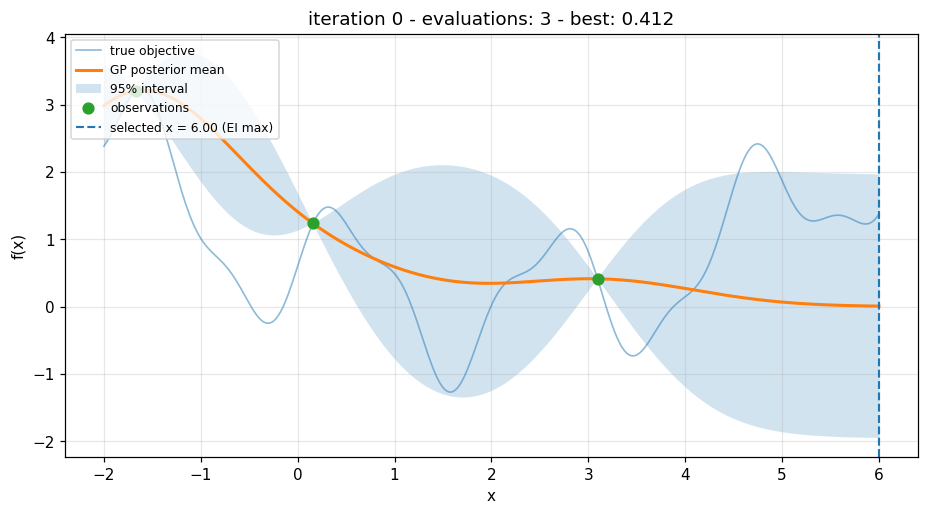

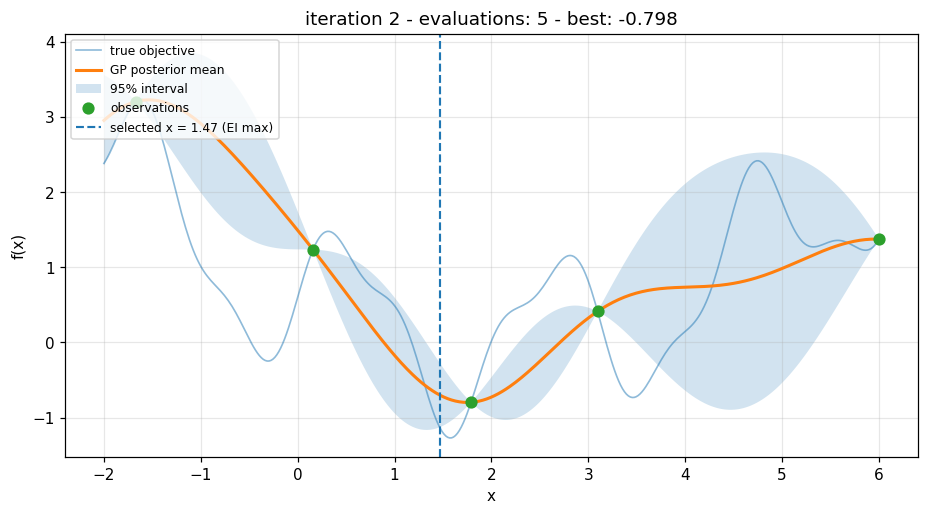

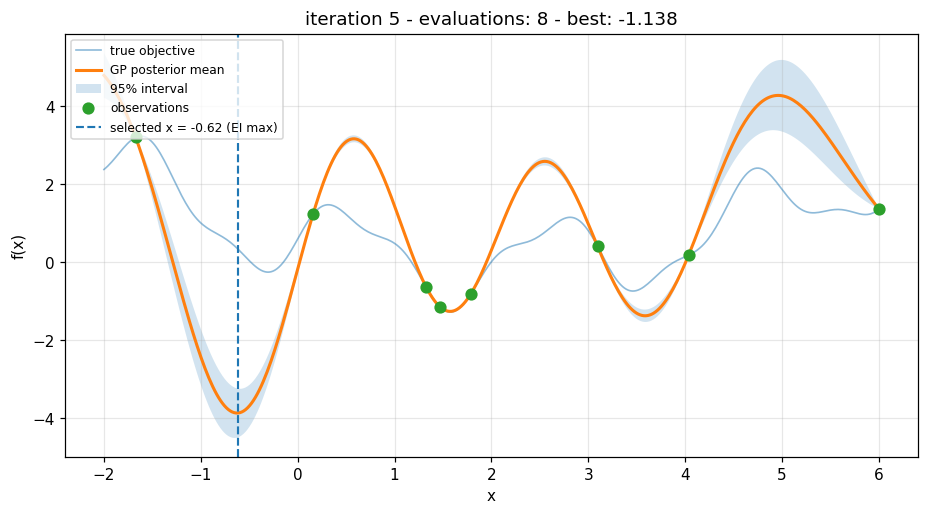

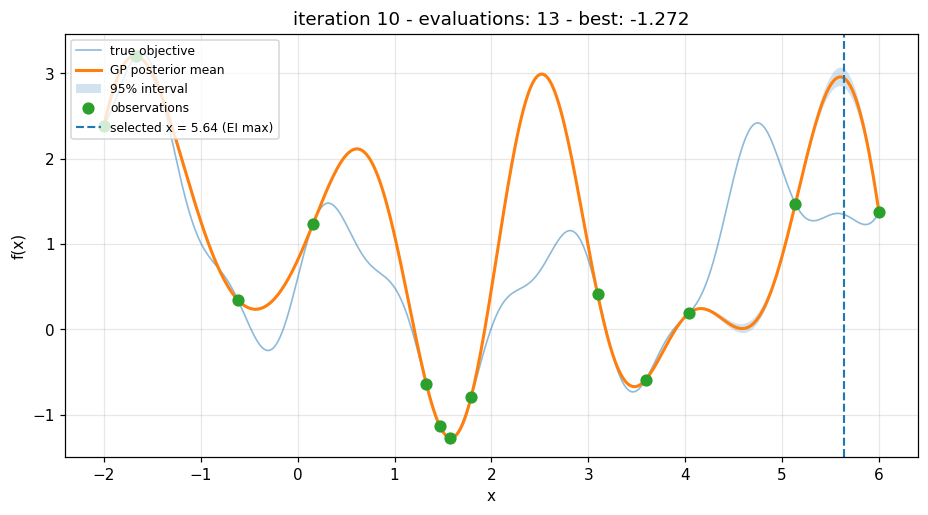

In [23]:
for it in [0, 2, 5, 10]:
    plot_bo_iteration(history[it], grid_bo,
                      fname=f"10_bo_iter_{it:02d}.png")


그림을 순서대로 보면:

- **iteration 0**: 아직 점이 3개뿐이라 신뢰구간이 넓고, 선택점은 정보가 부족한 영역에 있다.
- **iteration 2**: 관측이 늘면서 mean이 실제 곡선을 따라가기 시작한다.
- **iteration 5**: 좋은 영역(local minimum 근처)에 점이 몰리기 시작한다.
- **iteration 10**: 거의 global minimum 주변에 집중된다.

또 하나 눈여겨볼 것: 관측점이 지나치게 겹치지 않는다. EI가 0이 되는 이미 아는 곳은 선택되지 않기 때문이다.
**같은 점을 두 번 평가하는 것은 낭비**이고, EI는 이를 구조적으로 피한다.


## Section 13. Random Search vs Bayesian Optimization

공정한 비교를 위해 **평가 횟수를 맞춘다**. BO는 `n_initial=3` + `n_iterations=12` = 15회, Random Search도 15회.
BO는 최초 포인트 3개를 random으로 뽑으므로, **처음 3회는 두 방법이 사실상 동일**하다. 이후 12회가 차이다.

비교 지표는 `best_so_far` (지금까지 찾은 최소값)이다.

```python
best_so_far = np.minimum.accumulate(y)
```


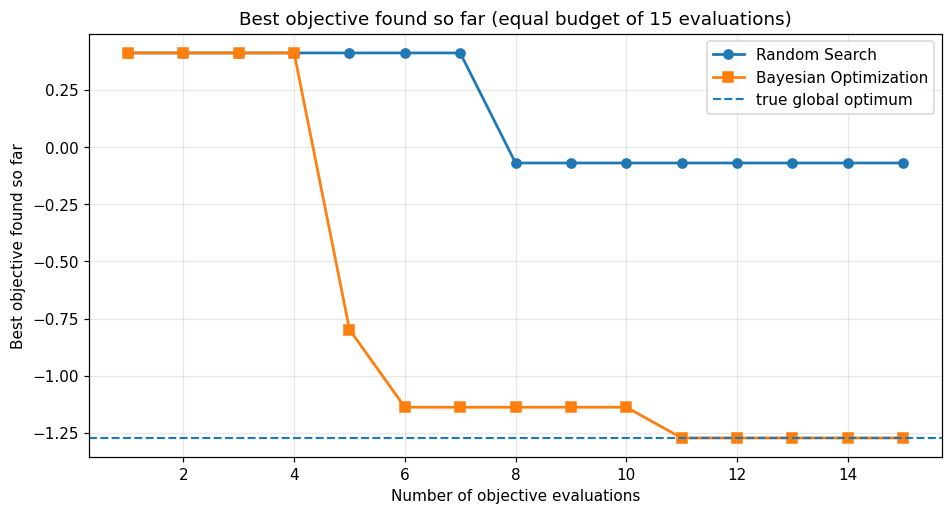

Random Search      final best = -0.0693  (regret 1.2034)
Bayesian Optim.    final best = -1.2721  (regret 0.0006)


In [24]:
X_rs15, y_rs15 = random_search(objective, BOUNDS, n_evals=15, seed=0)

best_rs = np.minimum.accumulate(y_rs15)
best_bo = np.minimum.accumulate(y_bo)
evals = np.arange(1, len(best_rs) + 1)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(evals, best_rs, marker="o", linewidth=1.8, label="Random Search")
ax.plot(evals, best_bo, marker="s", linewidth=1.8, label="Bayesian Optimization")
ax.axhline(GLOBAL_F, linestyle="--", linewidth=1.4, label="true global optimum")
ax.set_title("Best objective found so far (equal budget of 15 evaluations)")
ax.set_xlabel("Number of objective evaluations")
ax.set_ylabel("Best objective found so far")
ax.legend()
fig.savefig(os.path.join(FIG_DIR, "11_rs_vs_bo.png"), bbox_inches="tight")
plt.show()

print(f"Random Search      final best = {best_rs[-1]:.4f}  (regret {best_rs[-1] - GLOBAL_F:.4f})")
print(f"Bayesian Optim.    final best = {best_bo[-1]:.4f}  (regret {best_bo[-1] - GLOBAL_F:.4f})")


여기서 정직하게 짚어야 할 점: **한 번의 seed 결과를 절대적인 우열로 해석하면 안 된다.**
Random Search가 15번 중 우연히 좋은 점을 뽑으면 BO를 이길 수도 있다. 그래서 다음 섹션에서 반복 실험을 한다.


## Section 14. 반복 실험 (30 seeds)

운의 영향을 제거하기 위해 seed를 바꿔 30번 반복하고, 각 방법의 **regret**을 비교한다.

$$\text{regret} = f_{\text{best-found}} - f_{\text{global}}$$

regret이 0에 가까울수록 좋다. 최종 regret의 mean / std / median을 보고, boxplot으로 분포를 확인한다.


In [25]:
N_SEEDS = 30
N_INIT = 3
N_ITER = 12
BUDGET = N_INIT + N_ITER  # 15

regret_rs = np.zeros(N_SEEDS)
regret_bo = np.zeros(N_SEEDS)

for s in range(N_SEEDS):
    _, y_s = random_search(objective, BOUNDS, n_evals=BUDGET, seed=s)
    _, y_b, _, _ = bayesian_optimization(
        objective, BOUNDS, n_initial=N_INIT, n_iterations=N_ITER,
        seed=s, verbose=False)
    regret_rs[s] = np.min(y_s) - GLOBAL_F
    regret_bo[s] = np.min(y_b) - GLOBAL_F

print(f"{'method':<20}{'mean':>10}{'std':>10}{'median':>10}{'max':>10}")
for name, r in [("Random Search", regret_rs), ("Bayesian Optim.", regret_bo)]:
    print(f"{name:<20}{r.mean():>10.4f}{r.std():>10.4f}{np.median(r):>10.4f}{r.max():>10.4f}")


method                    mean       std    median       max
Random Search           0.4361    0.4300    0.2728    1.5915
Bayesian Optim.         0.0493    0.1616    0.0054    0.8938


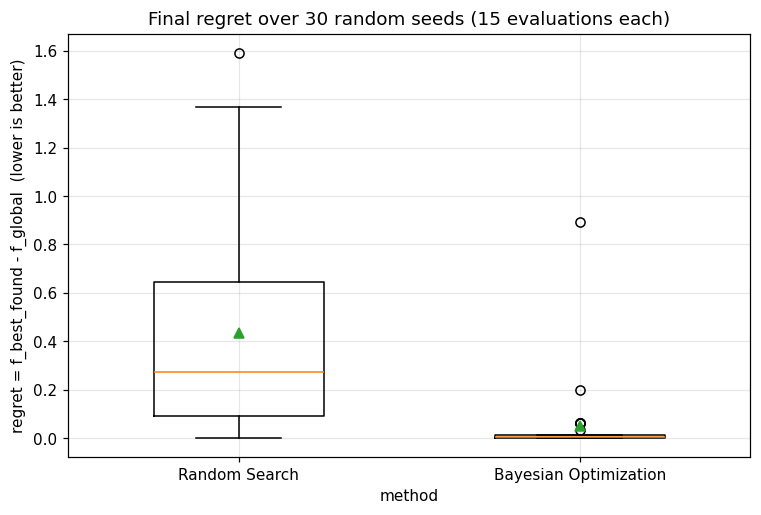

BO strictly better: 29/30  | ties: 0  | RS better: 1/30


In [26]:
fig, ax = plt.subplots(figsize=(8, 5))
bp = ax.boxplot([regret_rs, regret_bo],
                tick_labels=["Random Search", "Bayesian Optimization"],
                widths=0.5, showmeans=True)
ax.set_title(f"Final regret over {N_SEEDS} random seeds ({BUDGET} evaluations each)")
ax.set_ylabel("regret = f_best_found - f_global  (lower is better)")
ax.set_xlabel("method")
fig.savefig(os.path.join(FIG_DIR, "12_regret_boxplot_rs_vs_bo.png"), bbox_inches="tight")
plt.show()

wins_bo = int(np.sum(regret_bo < regret_rs - 1e-12))
ties = int(np.sum(np.abs(regret_bo - regret_rs) <= 1e-12))
print(f"BO strictly better: {wins_bo}/{N_SEEDS}  | ties: {ties}  "
      f"| RS better: {N_SEEDS - wins_bo - ties}/{N_SEEDS}")


**해석 포인트**

- mean과 median을 함께 봐야 한다. BO는 대부분의 seed에서 안정적으로 낮은 regret을 내는 경향이 있지만,
  RS가 우연히 아주 좋은 점을 뽑으면 RS의 최솟값이 튈 수 있다.
- std가 크다는 것은 "운에 따라 편차가 크다"는 뜻이다. 실무에서는 편차가 작은 쪽이 예측 가능성이 높다.
- 평가 예산이 15회로 매우 작다는 점을 기억하자. 예산이 커지면 RS도 결국 좋은 해를 찾고, 차이는 줄어든다.

### 학습 확인 질문

1. mean regret과 median regret이 다르게 나오는 이유는 무엇인가?
2. 이 실험에서 BO의 우위가 압도적이지 않다면, 그 원인을 두 가지 이상 들어 보라.


## Section 15. CMA-ES 소개

CMA-ES(Covariance Matrix Adaptation Evolution Strategy)는 Evolutionary Algorithm 계열의 대표적인 방법이다.
핵심 아이디어는 **좋은 해가 존재하는 search distribution 자체를 학습**하는 것이다.

$$x \sim \mathcal{N}(m, \sigma^2 C)$$

- $m$: 지금까지 좋은 해들이 모인 **중심**
- $\sigma$: 전체적인 **탐색 스케일**
- $C$: 탐색의 **방향과 상관관계**를 담은 covariance matrix

한 세대(generation)마다 population을 샘플링하고, 성능이 좋은 일부만 선택해서 $m, \sigma, C$를 업데이트한다.
$C$가 학습된다는 점이 단순 hill climbing과의 결정적 차이다.

### BO와의 철학적 차이

| | BO | CMA-ES |
|---|---|---|
| 무엇을 모델링하는가 | objective function $f$의 surrogate | 좋은 해가 있을 search distribution |
| uncertainty | $\sigma(x)$를 명시적으로 사용 | population의 spread로 암묵적으로 존재 |
| 평가당 정보 | 1점을 아주 비싸게 여김 | population 전체를 한 세대로 처리 |
| 병렬화 | 어색함 (다음 점이 이전 점에 의존) | 매우 자연스러움 (population을 동시에 평가) |

**BO**: 적은 수의 아주 비싼 평가, 낮은 차원, 매끄러운 objective에서 강하다.
**CMA-ES**: 중간~높은 차원, 노이즈가 크거나 매끄럽지 않은 objective, 병렬 평가 환경에서 강하다.


## Section 16. CMA-ES 실험

`cma` 패키지로 같은 objective를 최적화한다.

주의: CMA-ES는 **population 단위**로 평가하므로 평가 횟수를 정확히 15로 맞출 수 없다.
`cma`의 `maxfevals`는 세대 경계에서만 확인되므로, `popsize=5, maxfevals=15`는 3세대(15회)가 아니라
**4세대(20회)** 로 끝날 수 있다. 이건 버그가 아니라 population 기반 알고리즘의 구조적 성질이다.

여기서는 실제로 사용한 평가 횟수를 그대로 보여주고, 비교할 때 이 차이를 명시한다.
(즉 아래 비교에서 CMA-ES는 약 33% 더 많은 예산을 쓴 셈이다. 결과 해석 시 감안해야 한다.)

공정성을 위해 평가 궤적(best-so-far)을 **실제 평가 횟수** 기준으로 그린다.


In [27]:
import cma


def run_cmaes(objective, bounds, max_evals=15, popsize=5, sigma0=2.0, seed=0, verbose=False):
    """CMA-ES를 실행하고 평가 이력을 순서대로 기록한다.

    Notes
    -----
    `cma`의 'seed' 옵션은 'randn'이 np.random.randn일 때만 동작한다.
    bounds를 주면 내부 sampler가 다른 randn을 쓰므로 seed가 조용히 무시되어
    결과가 전역 RNG 상태에 의존하게 된다(재현 불가). 그래서 여기서는
    명시적인 RandomState를 randn으로 주입한다.

    Returns
    -------
    X : 평가한 x들
    y : 대응하는 f(x)들
    """
    low, high = bounds
    X_log, y_log = [], []

    rng = np.random.RandomState(seed)

    def randn(*size):
        """cma가 요구하는 randn(size) / randn(n, m) 시그니처를 맞춘다."""
        return rng.standard_normal(size[0] if len(size) == 1 else size)

    def wrapped(x):
        xi = float(np.clip(np.asarray(x).ravel()[0], low, high))
        yi = float(objective(np.array([xi]))[0])
        X_log.append(xi)
        y_log.append(yi)
        return yi

    x0 = 0.5 * (low + high)
    es = cma.CMAEvolutionStrategy(
        [x0], sigma0,
        {"maxfevals": max_evals, "popsize": popsize, "randn": randn,
         "verbose": -9, "bounds": [low, high]})
    while not es.stop():
        candidates = es.ask()
        values = [wrapped(c) for c in candidates]
        es.tell(candidates, values)

    return np.array(X_log), np.array(y_log)


X_cma, y_cma = run_cmaes(objective, BOUNDS, max_evals=15, popsize=5, seed=0)

print(f"CMA-ES evaluations used = {len(y_cma)}")
print(f"best x = {X_cma[int(np.argmin(y_cma))]:.4f}")
print(f"best f = {np.min(y_cma):.4f}")
print(f"regret = {np.min(y_cma) - GLOBAL_F:.4f}")


CMA-ES evaluations used = 20
best x = 1.5719
best f = -1.2725
regret = 0.0002


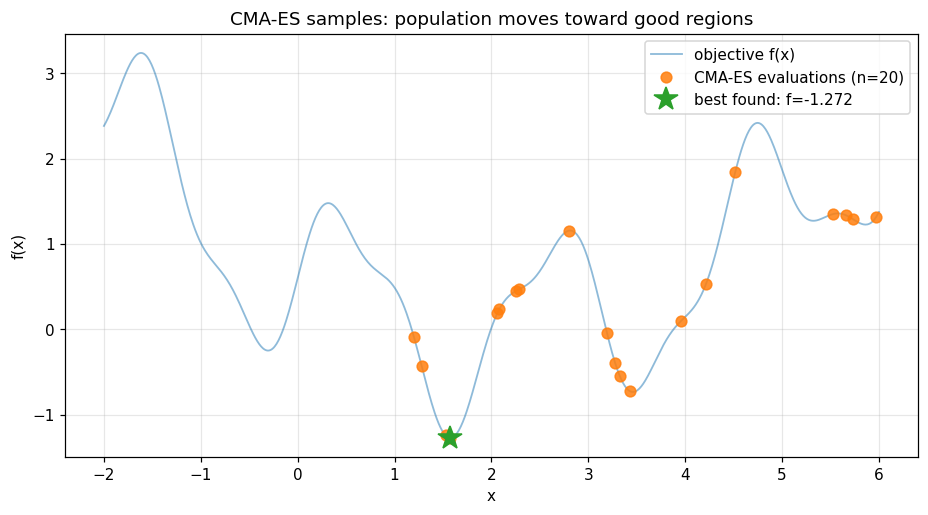

In [28]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(x_plot, objective(x_plot), linewidth=1.2, alpha=0.5, label="objective f(x)")
ax.plot(X_cma, y_cma, "o", markersize=7, alpha=0.85,
        label=f"CMA-ES evaluations (n={len(y_cma)})")
ax.plot(X_cma[int(np.argmin(y_cma))], np.min(y_cma), "*", markersize=16,
        label=f"best found: f={np.min(y_cma):.3f}")
ax.set_title("CMA-ES samples: population moves toward good regions")
ax.set_xlabel("x")
ax.set_ylabel("f(x)")
ax.legend()
fig.savefig(os.path.join(FIG_DIR, "13_cmaes_samples.png"), bbox_inches="tight")
plt.show()


### 구현 함정: `cma`의 seed는 bounds와 함께 쓰면 무시된다

`cma` 소스에서 seed는 다음 조건에서만 적용된다.

```python
if self.opts['randn'] is np.random.randn:
    np.random.seed(opts['seed'])
else:
    print_warning("seed will never be used")
```

`bounds`(또는 `fixed_variables`, `transformation`)를 지정하면 내부 sampler가 **다른 randn**을 쓰기 때문에
`'seed': 0`을 줘도 조용히 무시된다. 그러면 결과가 전역 `np.random` 상태에 의존해서,
앞 셀에서 난수를 얼마나 뽑았는지에 따라 결과가 달라진다. (재현 불가 + 간헐적 수치 오류까지 발생한다.)

해결책은 위 코드처럼 재현 가능한 `RandomState`를 `randn` 옵션으로 **직접 주입**하는 것이다.

> 교육 포인트: 라이브러리의 seed 옵션이 항상 모든 randomness를 지배한다고 가정하지 말 것.
> 재현성을 확인하는 가장 빠른 방법은 **같은 스크립트를 두 번 돌려 출력이 같은지 보는 것**이다.

CMA-ES의 점들은 BO와 다르게 **여러 개가 동시에** 나타난다. 이것이 population 기반 방법의 특징이다.
population이 좋은 영역으로 이동하면서 $\sigma$가 줄어들고, 후보들이 한 곳에 수렴한다.

### 학습 확인 질문

1. CMA-ES의 randomness는 Random Search의 randomness와 무엇이 다른가?
2. covariance matrix $C$는 무엇을 학습하는가?
3. 평가를 병렬로 해야 하는 상황에서 CMA-ES가 BO보다 유리한 이유는 무엇인가?


## Section 17. BO vs CMA-ES 정리

| 특성 | BO | CMA-ES |
|---|---|---|
| 핵심 아이디어 | surrogate model | search distribution |
| uncertainty | 명시적으로 사용 ($\sigma(x)$) | 보통 없음 (population spread) |
| sample efficiency | 높음 (수십 회 이내) | 상대적으로 낮음 |
| 많은 평가 가능 | 보통 | 강함 |
| parallel evaluation | 어색함 | 매우 자연스러움 |
| 저차원 + 비싼 objective | **강함** | 가능 |
| 고차원 / 복잡한 landscape | 어려워질 수 있음 | 상대적으로 강함 |
| 하이퍼파라미터 | kernel, $\xi$, 노이즈 | $\sigma_0$, popsize |

핵심 문장: **BO는 "평가 한 번이 비싸다"는 상황에 최적화되어 있고, CMA-ES는 "평가를 많이, 병렬로 할 수 있다"는 상황에 최적화되어 있다.**


## Section 18. Random Search vs BO vs CMA-ES

세 알고리즘을 같은 objective, 같은 예산(≈15회)에서 비교한다.
x축은 **Number of objective evaluations**로 통일한다.

주의: 하나의 random seed 결과를 절대적인 우열로 설명하지 않는다. 아래 그래프는 "한 번의 예시"이고,
뒤에서 반복 실험으로 분포를 확인한다.


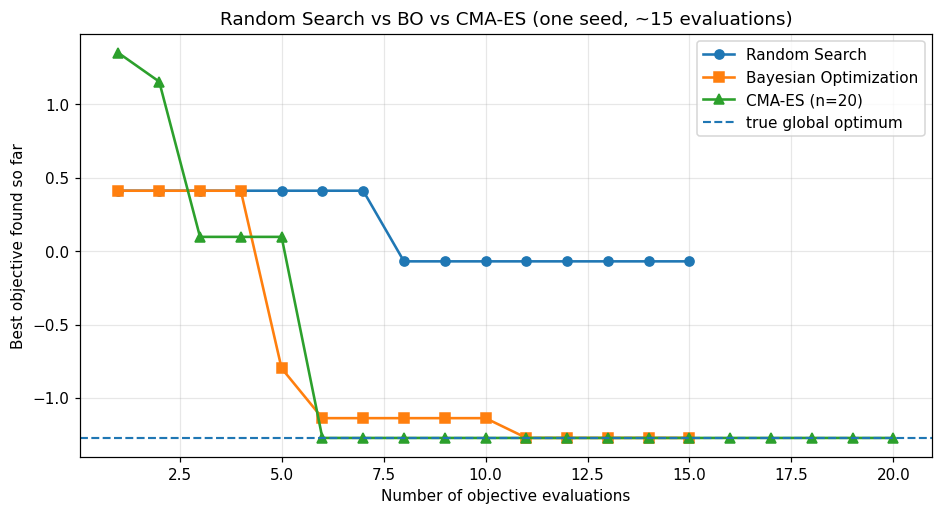

RS     final -0.0693
BO     final -1.2721
CMA-ES final -1.2725


In [29]:
best_rs_s0 = np.minimum.accumulate(y_rs15)
best_bo_s0 = np.minimum.accumulate(y_bo)
best_cma_s0 = np.minimum.accumulate(y_cma)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(np.arange(1, len(best_rs_s0) + 1), best_rs_s0, marker="o", linewidth=1.7,
        label="Random Search")
ax.plot(np.arange(1, len(best_bo_s0) + 1), best_bo_s0, marker="s", linewidth=1.7,
        label="Bayesian Optimization")
ax.plot(np.arange(1, len(best_cma_s0) + 1), best_cma_s0, marker="^", linewidth=1.7,
        label=f"CMA-ES (n={len(best_cma_s0)})")
ax.axhline(GLOBAL_F, linestyle="--", linewidth=1.4, label="true global optimum")
ax.set_title("Random Search vs BO vs CMA-ES (one seed, ~15 evaluations)")
ax.set_xlabel("Number of objective evaluations")
ax.set_ylabel("Best objective found so far")
ax.legend()
fig.savefig(os.path.join(FIG_DIR, "14_three_way.png"), bbox_inches="tight")
plt.show()

print(f"RS     final {best_rs_s0[-1]:.4f}")
print(f"BO     final {best_bo_s0[-1]:.4f}")
print(f"CMA-ES final {best_cma_s0[-1]:.4f}")


### 반복 실험으로 확인

seed만 바꿔 15회 반복해서 세 방법의 최종 regret 분포를 본다. (CMA-ES는 실행 시간이 더 걸리므로 seed 수를 줄였다.)


In [30]:
N_SEEDS_3 = 15
reg_rs3 = np.zeros(N_SEEDS_3)
reg_bo3 = np.zeros(N_SEEDS_3)
reg_cma3 = np.zeros(N_SEEDS_3)

for s in range(N_SEEDS_3):
    _, y_s = random_search(objective, BOUNDS, n_evals=BUDGET, seed=s)
    _, y_b, _, _ = bayesian_optimization(objective, BOUNDS, n_initial=N_INIT,
                                        n_iterations=N_ITER, seed=s, verbose=False)
    _, y_c = run_cmaes(objective, BOUNDS, max_evals=BUDGET, popsize=5, seed=s)
    reg_rs3[s] = np.min(y_s) - GLOBAL_F
    reg_bo3[s] = np.min(y_b) - GLOBAL_F
    reg_cma3[s] = np.min(y_c) - GLOBAL_F

print(f"{'method':<20}{'mean':>10}{'std':>10}{'median':>10}")
for name, r in [("Random Search", reg_rs3), ("Bayesian Optim.", reg_bo3), ("CMA-ES", reg_cma3)]:
    print(f"{name:<20}{r.mean():>10.4f}{r.std():>10.4f}{np.median(r):>10.4f}")


method                    mean       std    median
Random Search           0.3306    0.3215    0.2013
Bayesian Optim.         0.0838    0.2224    0.0020
CMA-ES                  0.1468    0.1920    0.0474


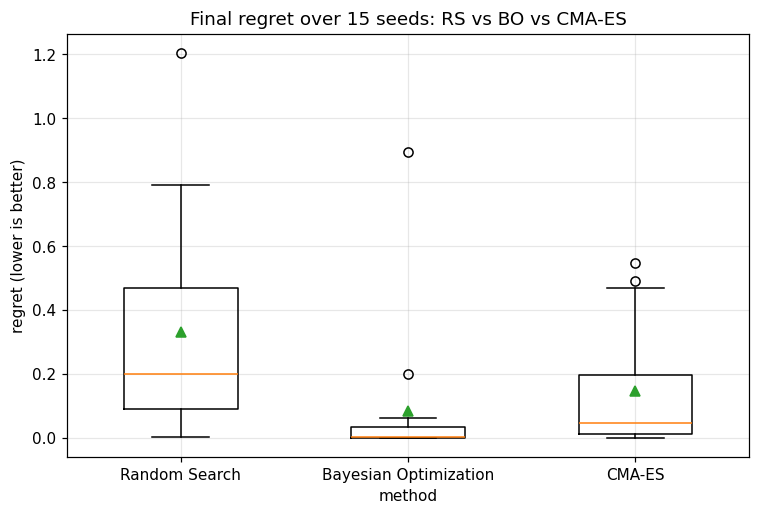

In [31]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.boxplot([reg_rs3, reg_bo3, reg_cma3],
           tick_labels=["Random Search", "Bayesian Optimization", "CMA-ES"],
           widths=0.5, showmeans=True)
ax.set_title(f"Final regret over {N_SEEDS_3} seeds: RS vs BO vs CMA-ES")
ax.set_ylabel("regret (lower is better)")
ax.set_xlabel("method")
fig.savefig(os.path.join(FIG_DIR, "15_regret_boxplot_three_way.png"), bbox_inches="tight")
plt.show()


**결과 해석 가이드**

- 이 toy problem은 1차원이고 objective가 매끄러우며, 예산이 15회로 극히 작다.
  이 조건은 **BO에게 유리한 조건**이다. 그래도 CMA-ES가 나쁘지 않다면, 그것은 1D 문제에서 population이 곧 넓은 탐색이 되기 때문이다.
- CMA-ES는 한 세대에 5개를 평가한다. 즉 15회 예산이면 **3~4세대**뿐이다. 세대 수가 적으면 $C$를 학습할 시간이 없다.
  CMA-ES가 진짜 강해지는 것은 예산이 수백 회 이상일 때다. 참고로 이 비교에서 CMA-ES는 20회를 평가했으므로 예산상 약간 유리했다.
- 반대로 BO는 15회 안에서도 "다음 한 점"을 매번 신중하게 고른다. **평가가 1회당 몇 시간 걸리는 상황**이라면 BO가 압도적이다.

### 학습 확인 질문

1. 1D 문제에서 CMA-ES의 population 크기가 5라는 것은 탐색 관점에서 어떤 의미인가?
2. 평가 예산이 15회에서 500회로 늘어난다면, 세 방법의 순위는 어떻게 바뀔 것으로 예상하는가?


## Section 19. 최종 개념 정리

### concept map

```text
Random Search
    |
    | previous trials를 활용하지 않음
    v
무작위 next candidate


Bayesian Optimization
    |
    | GP surrogate
    | mu(x), sigma(x)
    | acquisition
    v
next experiment


Evolutionary Algorithm (CMA-ES)
    |
    | population
    | selection
    | mutation / crossover
    v
next generation
```

### 세 문장으로 정리

**Random Search**

```text
Search space 전체에서 무작위로 후보를 뽑는다.
```

**Bayesian Optimization**

```text
과거 관측으로 objective를 모델링하고,
가장 가치 있는 다음 실험점을 선택한다.
```

**CMA-ES**

```text
좋은 후보들이 존재하는 search distribution을 반복적으로 개선한다.
```

### 수식 → 코드 대응표

| 개념 | 수식 | 코드 |
|---|---|---|
| RBF kernel | $k(x,x')=\sigma_f^2 e^{-(x-x')^2/2\ell^2}$ | `rbf_kernel` |
| GP posterior mean | $K_*^{\top}(K+\sigma_n^2I)^{-1}y$ | `gp_posterior` |
| GP posterior variance | $K_{**}-K_*^{\top}(K+\sigma_n^2I)^{-1}K_*$ | `gp_posterior` |
| EI | $(f_{\text{best}}-\mu-\xi)\Phi(Z)+\sigma\phi(Z)$ | `expected_improvement` |
| next point | $\arg\max_x EI(x)$ | `bayesian_optimization` |
| best-so-far | $\min_{i\le t} y_i$ | `np.minimum.accumulate` |
| regret | $f_{\text{best-found}}-f_{\text{global}}$ | Section 14 |

### 한 문장 요약

> GP는 지금까지 관측한 데이터로 black-box objective의 posterior mean과 uncertainty를 주고,
> BO는 이 surrogate와 acquisition function으로 **다음에 평가할 가장 가치 있는 위치**를 고른다.
> Random Search는 이전 결과를 버리지만 BO는 모든 관측을 다음 실험 설계에 활용한다.
> CMA-ES는 objective를 모델링하지 않고 **좋은 해가 있을 search distribution**을 학습한다.


---
# 추가 실험

여기서부터는 hyperparameter가 결과에 어떤 영향을 주는지 확인한다.
각 실험은 "왜 이런 일이 일어나는가"를 먼저 예측한 뒤 실행해 보기 바란다.

## Experiment A — length scale 변화

$\ell \in \{0.2, 0.5, 1.0, 2.0\}$로 바꾸며 GP posterior가 어떻게 달라지는지 본다.

예상:

- 너무 작으면 ($\ell=0.2$) 관측점 사이에서 mean이 0으로 급격히 돌아가고 uncertainty가 커진다 → 과소평활
- 너무 크면 ($\ell=2.0$) mean이 실제 곡선의 굴곡을 따라가지 못한다 → 과대평활


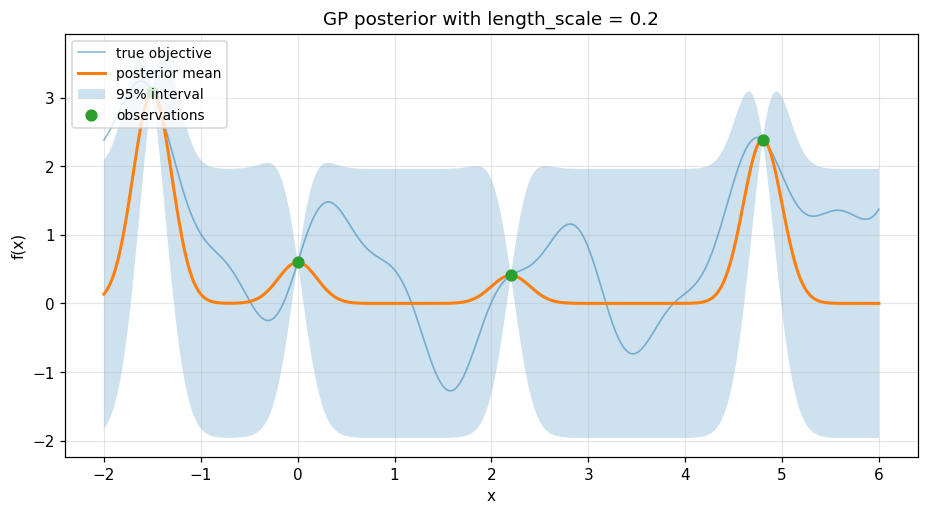

length_scale=0.2  | mean |error| on grid = 0.6981


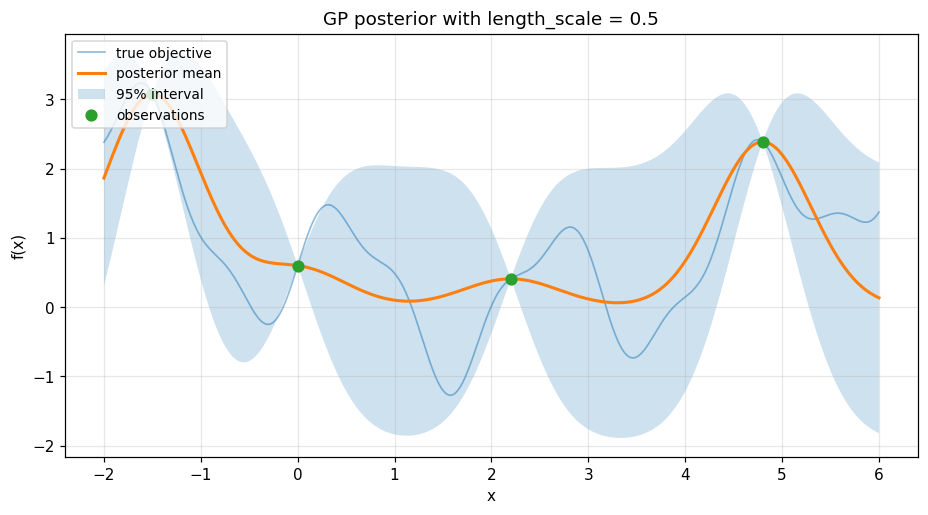

length_scale=0.5  | mean |error| on grid = 0.5692


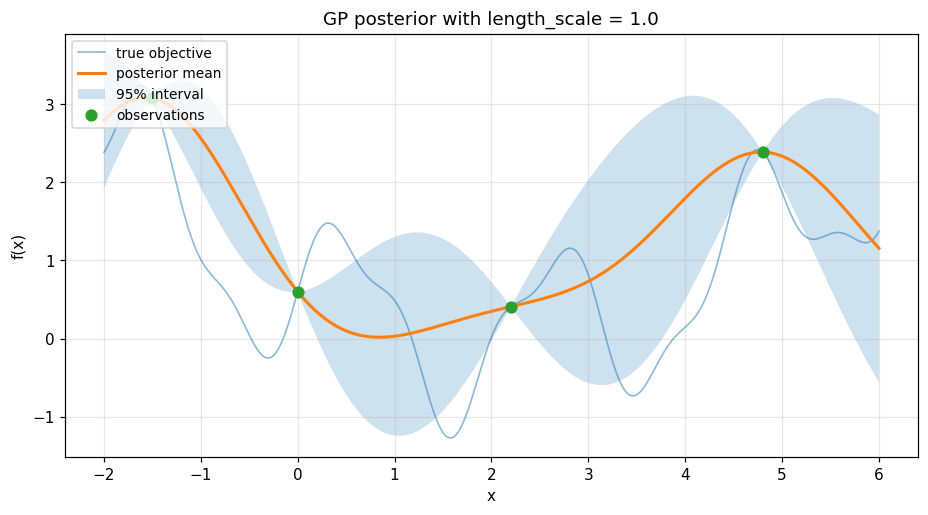

length_scale=1.0  | mean |error| on grid = 0.7971


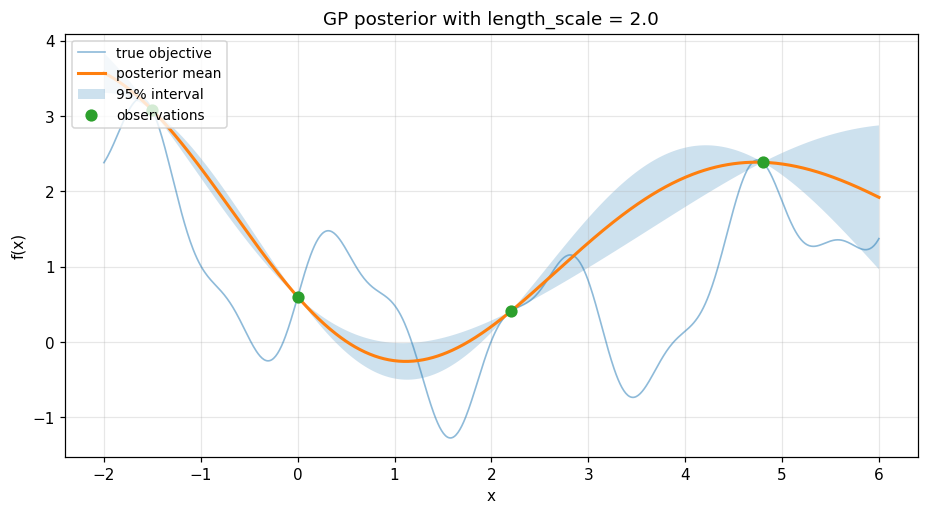

length_scale=2.0  | mean |error| on grid = 0.8908


In [32]:
for ell in [0.2, 0.5, 1.0, 2.0]:
    mu_l, var_l = gp_posterior(X_train, y_train, x_plot, length_scale=ell, sigma_n=1e-6)
    std_l = np.sqrt(var_l)

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.plot(x_plot, objective(x_plot), linewidth=1.1, alpha=0.5, label="true objective")
    ax.plot(x_plot, mu_l, linewidth=2.0, label="posterior mean")
    ax.fill_between(x_plot, mu_l - 1.96 * std_l, mu_l + 1.96 * std_l, alpha=0.22,
                    label="95% interval")
    ax.plot(X_train, y_train, "o", markersize=7, label="observations")
    ax.set_title(f"GP posterior with length_scale = {ell}")
    ax.set_xlabel("x")
    ax.set_ylabel("f(x)")
    ax.legend(loc="upper left", fontsize=9)
    fig.savefig(os.path.join(FIG_DIR, f"20_len_scale_{ell}.png"), bbox_inches="tight")
    plt.show()

    print(f"length_scale={ell:<4} | mean |error| on grid = "
          f"{np.mean(np.abs(objective(x_plot) - mu_l)):.4f}")


출력의 평균 절대오차를 비교해 보자. 이 4개 관측점(간격이 넓고 불규칙하다)에 대해서는 $\ell=0.5$가 가장 낮은 오차를 준다.
$\ell=0.2$는 관측점 사이에서 mean이 0으로 급격히 돌아가고, $\ell=1.0, 2.0$은 실제 굴곡을 놓쳐 **과대평활**된다.
즉 최적의 $\ell$은 **관측점의 밀도와 함수의 실제 굴곡**에 달려 있다. 관측점이 많아지면 최적 $\ell$은 작아지는 경향이 있다.

실무에서는 이 $\ell$을 **marginal likelihood를 최대화**해서 자동으로 정한다 (이 Notebook에서는 다루지 않는다).
hyperparameter를 사람이 고정한다는 것이 BO를 쓸 때 가장 번거로운 부분 중 하나다.


## Experiment B — observation noise 변화

$\sigma_n \in \{0, 0.1, 0.5\}$로 바꾼다. 관측에 노이즈가 있다고 가정하면 GP는 관측값을 **정확히 지나가지 않으려 한다**.
그래서 uncertainty가 0으로 완전히 줄지 않는다.


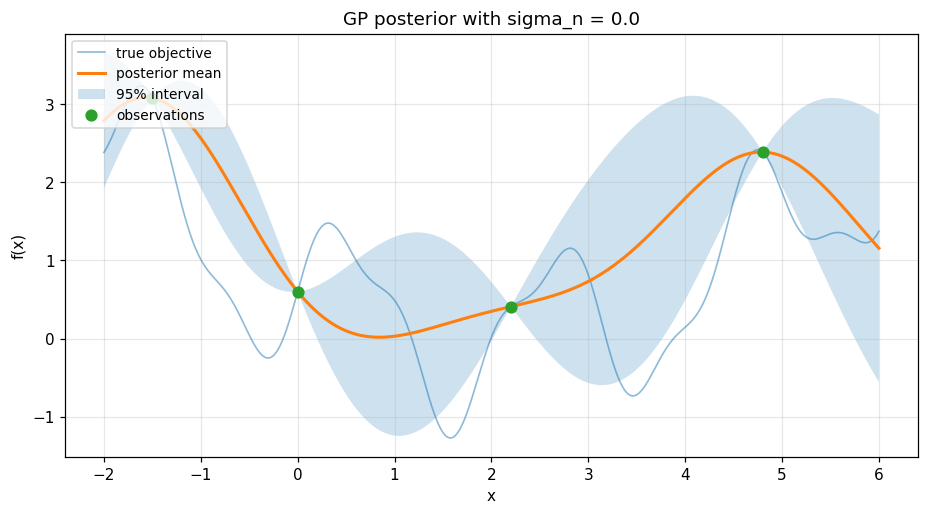

sigma_n=0.0  | std at observed points = [0. 0. 0. 0.]


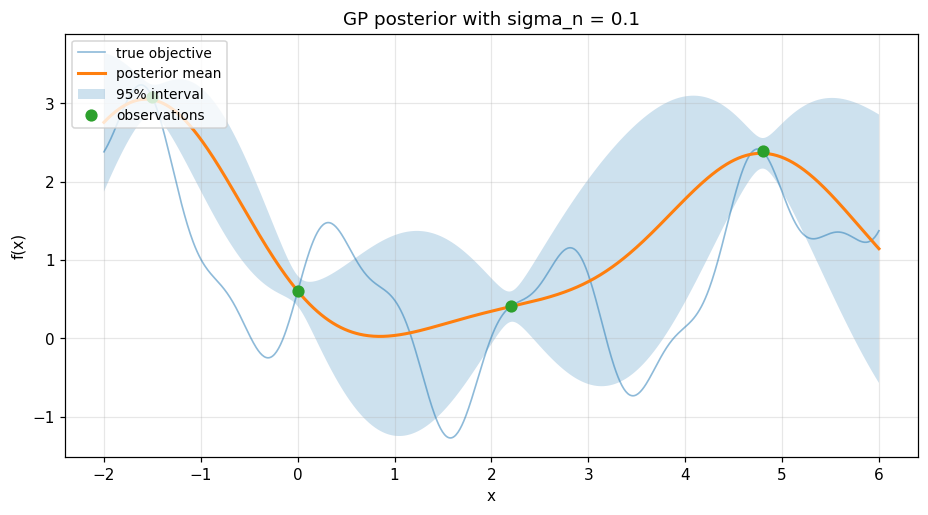

sigma_n=0.1  | std at observed points = [0.0994 0.0994 0.0995 0.0995]


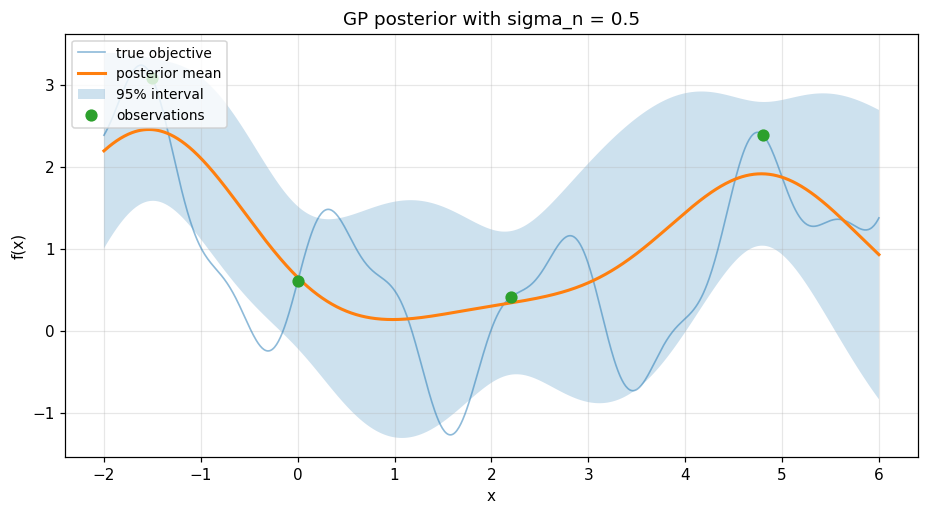

sigma_n=0.5  | std at observed points = [0.4431 0.4428 0.4469 0.4472]


In [33]:
for sigma_n in [0.0, 0.1, 0.5]:
    sn = max(sigma_n, 1e-8)   # sigma_n=0 -> 수치적 안정을 위해 아주 작은 값
    mu_n, var_n = gp_posterior(X_train, y_train, x_plot, length_scale=1.0, sigma_n=sn)
    std_n = np.sqrt(var_n)

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.plot(x_plot, objective(x_plot), linewidth=1.1, alpha=0.5, label="true objective")
    ax.plot(x_plot, mu_n, linewidth=2.0, label="posterior mean")
    ax.fill_between(x_plot, mu_n - 1.96 * std_n, mu_n + 1.96 * std_n, alpha=0.22,
                    label="95% interval")
    ax.plot(X_train, y_train, "o", markersize=7, label="observations")
    ax.set_title(f"GP posterior with sigma_n = {sigma_n}")
    ax.set_xlabel("x")
    ax.set_ylabel("f(x)")
    ax.legend(loc="upper left", fontsize=9)
    fig.savefig(os.path.join(FIG_DIR, f"21_noise_{sigma_n}.png"), bbox_inches="tight")
    plt.show()

    at_train = np.sqrt(gp_posterior(X_train, y_train, X_train, sigma_n=sn)[1])
    print(f"sigma_n={sigma_n:<4} | std at observed points = {np.round(at_train, 4)}")


$\sigma_n$이 커질수록 관측점에서도 std가 0이 되지 않는다. 이는 "측정값을 완전히 믿지 않는다"는 모델의 태도다.
실제 실험(센서 노이즈, stochastic simulation)에서는 이 설정이 필수적이다. $\sigma_n$을 0으로 두면 GP가 노이즈를 함수의 굴곡으로 착각한다.


## Experiment C — initial sample 수 변화

`n_initial` $\in \{2, 3, 5, 10\}$로 바꾸고, **총 예산은 15회로 고정**한 채 BO의 최종 regret을 비교한다.

trade-off:

- 초기점이 적으면 → BO가 일찍부터 EI로 유용한 곳을 고를 수 있다 (단, 초반 GP가 매우 부정확)
- 초기점이 많으면 → GP는 정확해지지만, EI를 쓸 기회(iteration 수)가 줄어든다


In [34]:
init_list = [2, 3, 5, 10]
N_SEEDS_INIT = 20
results_init = {}

for n_init in init_list:
    n_iter = BUDGET - n_init
    if n_iter <= 0:
        continue
    regs = []
    for s in range(N_SEEDS_INIT):
        _, y_b, _, _ = bayesian_optimization(
            objective, BOUNDS, n_initial=n_init, n_iterations=n_iter,
            seed=s, verbose=False)
        regs.append(np.min(y_b) - GLOBAL_F)
    results_init[n_init] = np.array(regs)
    r = results_init[n_init]
    print(f"n_initial={n_init:<3d} (n_iter={n_iter:<2d}) | mean={r.mean():.4f} "
          f"std={r.std():.4f} median={np.median(r):.4f}")


n_initial=2   (n_iter=13) | mean=0.0850 std=0.1597 median=0.0109


n_initial=3   (n_iter=12) | mean=0.0713 std=0.1942 median=0.0089


n_initial=5   (n_iter=10) | mean=0.0573 std=0.0905 median=0.0089
n_initial=10  (n_iter=5 ) | mean=0.1583 std=0.1636 median=0.0955


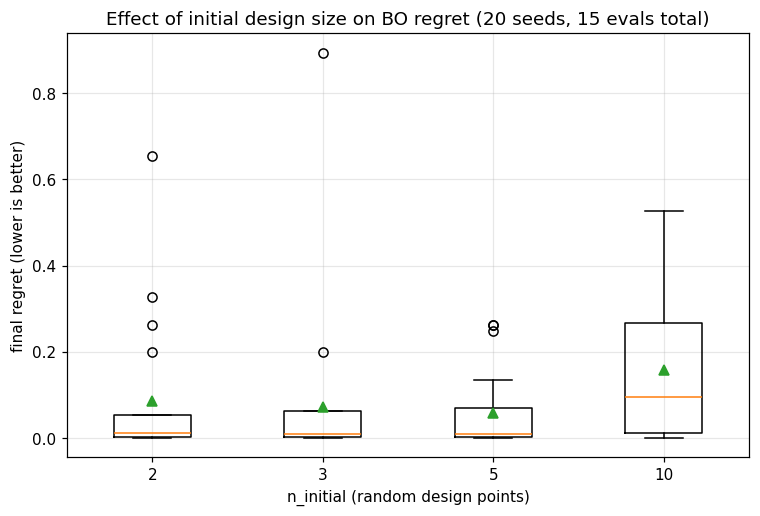

In [35]:
fig, ax = plt.subplots(figsize=(8, 5))
labels = [str(k) for k in results_init]
ax.boxplot([results_init[k] for k in results_init], tick_labels=labels, showmeans=True)
ax.set_title(f"Effect of initial design size on BO regret ({N_SEEDS_INIT} seeds, "
             f"{BUDGET} evals total)")
ax.set_xlabel("n_initial (random design points)")
ax.set_ylabel("final regret (lower is better)")
fig.savefig(os.path.join(FIG_DIR, "22_init_size.png"), bbox_inches="tight")
plt.show()


초기점이 너무 적으면 분산이 커지고, 너무 많으면 개선 기회가 줄어든다.
실무에서는 보통 $d+1$ (차원 + 1) 근처에서 시작하는 것이 관례다. 여기서는 $d=1$이므로 2~3이 합리적이다.


## Experiment D — EI의 exploration parameter $\xi$

$\xi \in \{0, 0.01, 0.1, 0.5\}$로 바꾼다.

$$\text{EI}(x) = (f_{\text{best}}-\mu(x)-\xi)\Phi(Z) + \sigma(x)\phi(Z)$$

$\xi$가 커지면 "$\mu$가 $f_{\text{best}}$보다 $\xi$만큼 더 좋아야 improvement로 인정"되므로,
mean이 좋은 곳의 매력이 줄고 상대적으로 $\sigma$가 큰 곳이 선택된다 → **exploration 증가**.


In [36]:
xi_list = [0.0, 0.01, 0.1, 0.5]
N_SEEDS_XI = 20
results_xi = {}

for xi in xi_list:
    regs = []
    for s in range(N_SEEDS_XI):
        _, y_b, _, _ = bayesian_optimization(
            objective, BOUNDS, n_initial=N_INIT, n_iterations=N_ITER,
            xi=xi, seed=s, verbose=False)
        regs.append(np.min(y_b) - GLOBAL_F)
    results_xi[xi] = np.array(regs)
    r = results_xi[xi]
    print(f"xi={xi:<5} | mean={r.mean():.4f} std={r.std():.4f} median={np.median(r):.4f}")


xi=0.0   | mean=0.0996 std=0.2202 median=0.0089


xi=0.01  | mean=0.0713 std=0.1942 median=0.0089


xi=0.1   | mean=0.1242 std=0.2082 median=0.0436


xi=0.5   | mean=0.2278 std=0.2085 median=0.1917


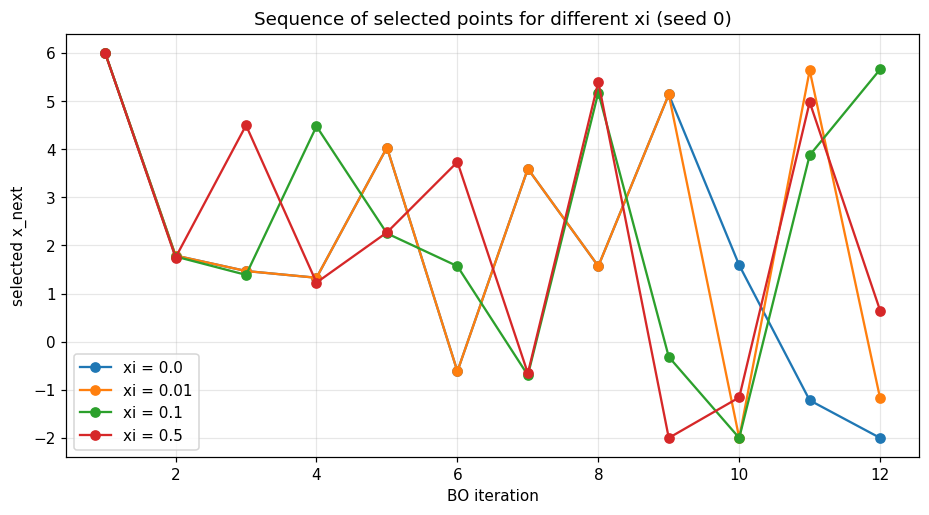

In [37]:
# xi가 클수록 선택점이 넓게 퍼지는지 한 눈에 확인
fig, ax = plt.subplots(figsize=(10, 5))
for xi in xi_list:
    _, _, hist_xi, grid_xi = bayesian_optimization(
        objective, BOUNDS, n_initial=N_INIT, n_iterations=N_ITER,
        xi=xi, seed=0, verbose=False)
    chosen = [h["x_next"] for h in hist_xi]
    ax.plot(np.arange(1, len(chosen) + 1), chosen, marker="o", linewidth=1.5,
            label=f"xi = {xi}")
ax.set_title("Sequence of selected points for different xi (seed 0)")
ax.set_xlabel("BO iteration")
ax.set_ylabel("selected x_next")
ax.legend()
fig.savefig(os.path.join(FIG_DIR, "23_xi_sequences.png"), bbox_inches="tight")
plt.show()


$\xi$가 큰 경우 선택점이 더 넓게 흩어지고(exploration), $\xi=0$인 경우 빠르게 한 곳에 붙는 경향이 있다.
단, 이 1D toy problem은 작아서 $\xi$의 효과가 크지 않을 수 있다. 효과가 고차원/복잡한 문제에서 더 분명해진다.


---
# 선택적 확장: 다른 Acquisition Function

EI 외에 자주 쓰이는 두 가지를 구현하고, **같은 posterior에서 어디를 선택하는지** 비교한다.

### Probability of Improvement (PI)

$$PI(x) = \Phi\left(\frac{f_{\text{best}}-\mu(x)-\xi}{\sigma(x)}\right)$$

"개선이 일어날 확률"만 보고, **개선의 크기는 무시**한다. 그래서 아주 작은 개선이라도 확률이 높으면 선택된다 → 지나치게 exploitation 편향.

### Lower Confidence Bound (LCB)

최소화 문제에서

$$LCB(x) = \mu(x) - \kappa\sigma(x)$$

"낙관적 하한"을 최소화한다. $\kappa$가 크면 exploration이 강해진다 (대표적으로 $\kappa=2$).


In [38]:
def probability_of_improvement(mu, sigma, best_y, xi=0.01):
    """Minimization 기준 PI."""
    mu = np.asarray(mu, dtype=float)
    sigma = np.maximum(np.asarray(sigma, dtype=float), 1e-12)
    Z = (best_y - mu - xi) / sigma
    return norm.cdf(Z)


def lower_confidence_bound(mu, sigma, kappa=2.0):
    """Minimization 기준 LCB (작을수록 좋은 점수)."""
    return np.asarray(mu, dtype=float) - kappa * np.asarray(sigma, dtype=float)


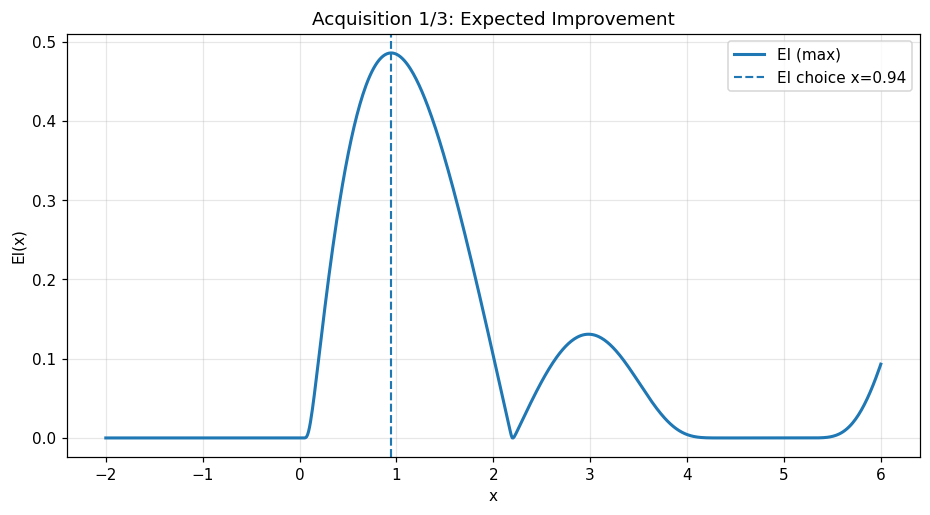

In [39]:
best_y_demo = float(np.min(y_train))
mu_d, var_d = gp_posterior(X_train, y_train, x_plot, length_scale=1.0, sigma_n=1e-6)
std_d = np.sqrt(var_d)

ei_d = expected_improvement(mu_d, std_d, best_y_demo, xi=0.01)
pi_d = probability_of_improvement(mu_d, std_d, best_y_demo, xi=0.01)
lcb_d = lower_confidence_bound(mu_d, std_d, kappa=2.0)

x_ei = x_plot[int(np.argmax(ei_d))]
x_pi = x_plot[int(np.argmax(pi_d))]
x_lcb = x_plot[int(np.argmin(lcb_d))]

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(x_plot, ei_d, linewidth=2.0, label="EI (max)")
ax.axvline(x_ei, linestyle="--", linewidth=1.4, label=f"EI choice x={x_ei:.2f}")
ax.set_title("Acquisition 1/3: Expected Improvement")
ax.set_xlabel("x")
ax.set_ylabel("EI(x)")
ax.legend()
fig.savefig(os.path.join(FIG_DIR, "30_acq_ei.png"), bbox_inches="tight")
plt.show()


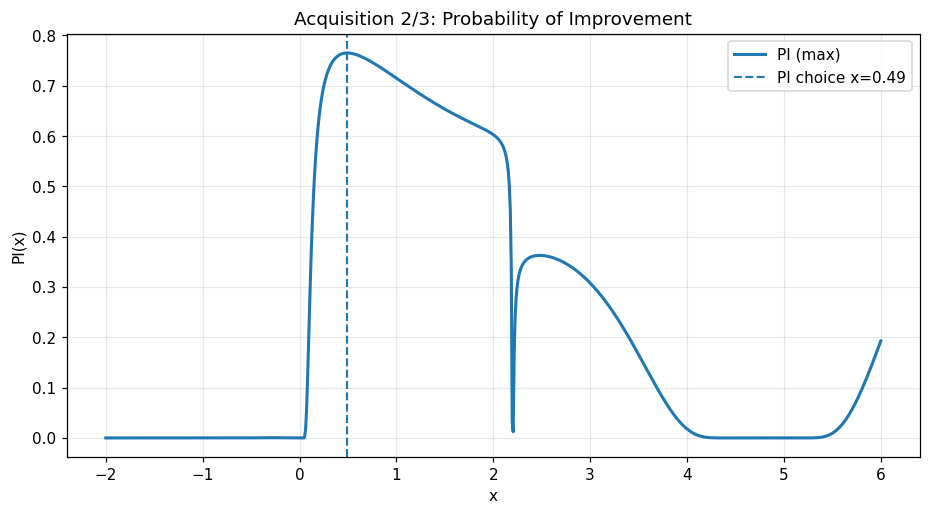

In [40]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(x_plot, pi_d, linewidth=2.0, label="PI (max)")
ax.axvline(x_pi, linestyle="--", linewidth=1.4, label=f"PI choice x={x_pi:.2f}")
ax.set_title("Acquisition 2/3: Probability of Improvement")
ax.set_xlabel("x")
ax.set_ylabel("PI(x)")
ax.legend()
fig.savefig(os.path.join(FIG_DIR, "31_acq_pi.png"), bbox_inches="tight")
plt.show()


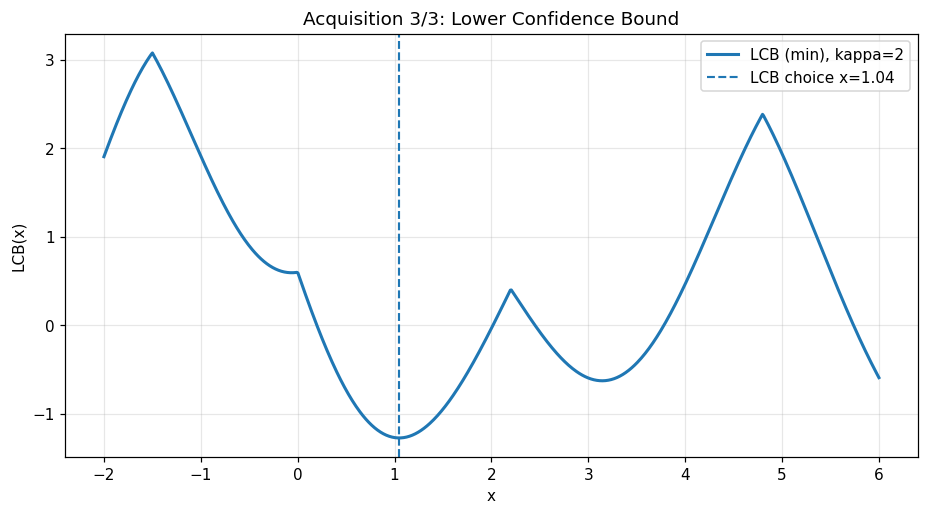

EI  selects x = 0.944
PI  selects x = 0.493
LCB selects x = 1.044  (kappa=2)


In [41]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(x_plot, lcb_d, linewidth=2.0, label="LCB (min), kappa=2")
ax.axvline(x_lcb, linestyle="--", linewidth=1.4, label=f"LCB choice x={x_lcb:.2f}")
ax.set_title("Acquisition 3/3: Lower Confidence Bound")
ax.set_xlabel("x")
ax.set_ylabel("LCB(x)")
ax.legend()
fig.savefig(os.path.join(FIG_DIR, "32_acq_lcb.png"), bbox_inches="tight")
plt.show()

print(f"EI  selects x = {x_ei:.3f}")
print(f"PI  selects x = {x_pi:.3f}")
print(f"LCB selects x = {x_lcb:.3f}  (kappa=2)")


세 acquisition function이 서로 다른 점을 선택할 수 있다는 것을 확인했으면 한다.

- **PI**는 확률만 보므로 이미 좋아 보이는 곳에 붙는 경향 (exploitation)
- **LCB**는 $\kappa$로 exploration을 조절할 수 있어 단순하고 강력하다
- **EI**는 개선의 **크기**까지 기대값에 반영하므로 균형이 좋아 가장 널리 쓰인다

### 학습 확인 질문

1. PI가 EI보다 exploitation에 치우치는 이유를 수식으로 설명해 보라.
2. LCB의 $\kappa$를 0으로 두면 어떤 전략이 되는가?


---
# 마무리: 스스로 확인할 것

다음 문장을 **자기 말로** 설명할 수 있으면 이 Notebook의 목표는 달성된 것이다.

1. Gaussian Process는 지금까지 관측한 데이터를 이용해 black-box objective의 posterior mean과 uncertainty를 제공한다.
2. Bayesian Optimization은 이 surrogate model과 acquisition function을 이용해 다음으로 평가할 가장 가치 있는 위치를 선택한다.
3. Random Search는 이전 결과를 활용하지 않지만, BO는 모든 관측 결과를 다음 실험 설계에 활용한다.
4. CMA-ES는 objective 자체를 surrogate로 모델링하지 않고, 좋은 해가 존재할 가능성이 높은 search distribution을 반복적으로 업데이트한다.
5. 따라서 BO와 EA/CMA-ES는 어느 한쪽이 항상 우월한 것이 아니라, evaluation budget과 search space 특성에 따라 적합성이 달라진다.

## 직접 해볼 것 (연습)

1. `objective`를 2D로 확장해 보라. (예: Rosenbrock 또는 Branin) GP posterior는 grid 대신 meshgrid에서 계산하고,
   EI는 argmax를 2D에서 찾으면 된다. 몇 차원부터 BO가 힘들어지는가?
2. `bayesian_optimization`에 **observation noise**를 추가하라. `y_next = objective(x_next) + noise`로 두고,
   GP의 `sigma_n`을 실제 노이즈에 맞춰 보라. `sigma_n`을 0으로 두면 무슨 일이 생기는가?
3. 더 이상 개선이 없을 때 BO를 멈추는 조건(예: EI 최댓값이 threshold 미만)을 구현해 보라.
4. `bayesian_optimization`에 **batch** 버전을 만들어 보라. EI를 하나 고르고, 그 점을 관측했다고 가정한 뒤
   다시 EI를 계산해 다음 점을 고르는 식("kriging believer")으로 병렬 평가를 흉내낼 수 있다.


---
## 참고문헌

- Rasmussen & Williams, *Gaussian Processes for Machine Learning*, MIT Press, 2006. (2장: regression, 5장: BO)
- Brochu, Cora & de Freitas, *A Tutorial on Bayesian Optimization of Expensive Cost Functions*, arXiv:1012.2599, 2010.
- Shahriari et al., *Taking the Human Out of the Loop: A Review of Bayesian Optimization*, Proc. IEEE, 2016.
- Hansen, *The CMA Evolution Strategy: A Tutorial*, arXiv:1604.00772, 2016.
- Jones, Schonlau & Welch, *Efficient Global Optimization of Expensive Black-Box Functions*, J. Global Optimization, 1998. (EI의 원 논문)
